# Parte 7: Árvores de Decisão e Random Forest

Classificação de `target_class` com árvores de decisão (DT) e Random Forest (RF), conforme pedido na
secção 7 do enunciado.

### Índice

1. Enquadramento teórico
2. Preparação dos dados
3. Árvore de decisão sem afinação, 7.1(a)
4. O compromisso viés-variância na árvore
5. Afinação da árvore de decisão, 7.1(b)
6. Árvore final e regras de decisão, 7.1(c)
7. Random Forest sem afinação, 7.2(a)
8. Número de árvores: Random Forest contra bagging
9. Afinação da Random Forest, 7.2(b)
10. Importância das variáveis, 7.2(c)
11. Comparação com a EDA e com Ridge e Lasso, 7.2(d)
12. Verificação: o conjunto completo de variáveis
13. Conclusões
14. Referências

## 1. Enquadramento teórico

**O que é uma árvore de decisão.** Uma árvore divide o espaço das variáveis em **regiões
retangulares**, através de uma sequência de perguntas binárias do tipo `HbA1c_level <= 6.67`. Cada
pergunta é um **nó interno**, e cada região final é uma **folha**. Numa árvore de classificação, cada
folha prevê a **classe mais frequente** entre os registos de treino que lá caem. Os cortes são sempre
paralelos aos eixos, nunca diagonais, o que torna a árvore fácil de ler mas pouco eficiente a captar
fronteiras oblíquas.

**Como se aprende.** Encontrar a melhor árvore possível não tem solução analítica. O scikit-learn usa
uma versão do **CART**, que é um algoritmo **guloso** (TDIDT, *top-down induction of decision trees*):
começa com todos os dados, escolhe a pergunta que mais reduz a **impureza** dos dois grupos
resultantes e repete o processo em cada grupo até um critério de paragem. Por ser guloso, não garante
o ótimo global.

**Medidas de impureza.** Para avaliar cada divisão usa-se o **índice de Gini** ou a **entropia**, e
não a taxa de erro, porque ambos são mais sensíveis à pureza dos nós. Um nó com uma só classe tem
impureza zero.

**O problema da árvore: variância.** Deixada crescer livremente, a árvore continua a dividir até as
folhas ficarem puras e acaba por **decorar** o treino. O resultado é um modelo excelente no treino e
fraco em dados novos. O tamanho controla-se com hiperparâmetros (`max_depth`,
`min_samples_leaf`, `max_leaf_nodes`) ou com **poda por custo-complexidade**, em que se penaliza cada
folha adicional com um custo α (`ccp_alpha`). O tamanho adequado escolhe-se por validação cruzada.

**Bagging e Random Forest.** Uma árvore isolada é **instável**: duas metades dos mesmos dados podem
dar árvores muito diferentes. A solução é treinar muitas árvores em amostras *bootstrap* e decidir por
**votação por maioria**. Fazer a média de B modelos independentes divide a variância por B, mas se os
modelos forem **correlacionados** a redução é muito menor. No *bagging* todas as árvores podem usar
todas as variáveis, e uma variável dominante aparece no topo de todas elas, tornando-as parecidas. A
**Random Forest** acrescenta uma segunda fonte de aleatoriedade: em cada divisão só pode escolher
entre **m variáveis sorteadas**, com m < p, o que **descorrelaciona** as árvores. O *bagging* é o caso
particular m = p.

| | Bagging | Random Forest |
|---|---|---|
| Variáveis candidatas em cada divisão | todas, m = p | subconjunto aleatório, m < p |
| O que varia entre árvores | só a amostra *bootstrap* | a amostra e as variáveis |
| No scikit-learn | `max_features=None` | `max_features='sqrt'` |

**Erro *out-of-bag* (OOB).** Cada amostra *bootstrap* deixa de fora cerca de um terço dos registos.
Esses registos servem de teste para a árvore que não os viu, o que dá uma estimativa de desempenho
sem custo adicional. A secção 7 mostra porque é que, com compensação de classes, esta estimativa não
pode ser usada neste problema.

**O compromisso.** A Random Forest prevê muito melhor do que uma árvore isolada, mas perde a sua
principal virtude, a **interpretabilidade**. Parte dela recupera-se com a **importância das
variáveis**.

## 2. Preparação dos dados

**Variáveis.** O enunciado obriga a usar, a partir desta tarefa, os preditores mais relevantes segundo
a Tarefa 5. Usa-se por isso o **conjunto reduzido de 15 variáveis** selecionado pelo Lasso na secção 8
dessa tarefa, que foi o único a **melhorar** o F1 macro em validação cruzada face ao conjunto completo,
de 0.6303 para 0.6472, e com menor dispersão entre partições. O conjunto de 11 variáveis foi posto de
parte porque perdia desempenho e duplicava a instabilidade.

**Divisão e codificação.** Repetem-se exatamente as decisões da Tarefa 5, para que os resultados sejam
comparáveis:
- divisão 75/25 **estratificada** com a semente 22, o que produz os mesmos registos de teste;
- variáveis categóricas convertidas em colunas binárias com `get_dummies`, mantendo a primeira
  categoria como referência.

**O que muda face aos modelos lineares.** As árvores **não precisam de padronização**: cada corte
compara uma variável com um limiar, e uma mudança de escala move o limiar sem alterar a divisão. Por
isso não há `StandardScaler` neste notebook.

**Validação.** Toda a afinação é feita por validação cruzada **estratificada de 5 partições, apenas no
treino**. O conjunto de teste só é usado para a avaliação final de cada modelo.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import kruskal, chi2_contingency, spearmanr

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate, cross_val_score, validation_curve)
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, recall_score,
                             precision_score, confusion_matrix)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 22
print('scikit-learn:', sklearn.__version__)

nome_ficheiro = 'dataset_grupo_22.csv'
caminhos = [Path.cwd() / nome_ficheiro, Path.cwd().parent / nome_ficheiro]
caminho = next((p for p in caminhos if p.is_file()), None)
if caminho is None:
    raise FileNotFoundError(f'Nao foi encontrado {nome_ficheiro}.')

df = pd.read_csv(caminho)
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

# Colunas removidas na analise exploratoria: constante, duplicadas e sem ligacao ao paciente
REMOVIDAS = ['calcium_baseline', 'age_normalized', 'systolic_index', 'ldl_alternative']
num_cols = [c for c in df.select_dtypes(include='number').columns
            if c not in REMOVIDAS + [TARGET_REG]]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

# Variaveis eliminadas pelo Lasso no conjunto reduzido de 15 (Tarefa 5, seccao 8, C = 0.1874)
ELIMINADAS_LASSO = ['age', 'alcohol_intake', 'bmi', 'cholesterol', 'diastolic_bp', 'family_history',
                    'gender', 'hdl', 'heart_rate', 'ldl', 'salt_intake', 'sleep_hours',
                    'stress_level', 'systolic_bp']
var_num = [c for c in num_cols if c not in ELIMINADAS_LASSO]
var_cat = [c for c in cat_cols if c not in ELIMINADAS_LASSO]
VARIAVEIS = var_num + var_cat

# Codificacao igual a da Tarefa 5: colunas binarias, com a primeira categoria como referencia
X = pd.get_dummies(df[VARIAVEIS], columns=var_cat, drop_first=True).astype(float)
y = df[TARGET_CLS]
colunas = list(X.columns)
classes = sorted(y.unique())

def variavel_de(coluna):
    """Variavel original a que pertence uma coluna codificada."""
    return next(v for v in VARIAVEIS if coluna == v or coluna.startswith(v + '_'))

# Mesma divisao da Tarefa 5: 75/25, estratificada, semente 22
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_repetida = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

print(f'Variaveis usadas: {len(var_num)} numericas + {len(var_cat)} categoricas = {len(VARIAVEIS)}')
print(' ', VARIAVEIS)
print(f'Colunas apos get_dummies: {len(colunas)}')
print(f'Treino: {len(X_train)} | Teste: {len(X_test)}')
print('\nContagens por classe (treino / teste):')
print(pd.DataFrame({'treino': y_train.value_counts(), 'teste': y_test.value_counts()}))

scikit-learn: 1.9.1
Variaveis usadas: 6 numericas + 9 categoricas = 15
  ['HbA1c_level', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'plasma_value', 'age_level', 'bmi_level', 'smoking', 'physical_activity', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']
Colunas apos get_dummies: 24
Treino: 1500 | Teste: 500

Contagens por classe (treino / teste):
              treino  teste
target_class               
DI_HY           1348    450
HT                88     29
DI_HT             64     21


**Conclusões:** As 15 variáveis dividem-se em 6 numéricas e 9 categóricas, que dão 24 colunas depois da
codificação. O treino tem 1500 registos e o teste 500, com as mesmas contagens por classe da Tarefa 5:
**apenas 64 registos `DI_HT` e 88 `HT` no treino**, contra 1348 `DI_HY`. No teste há só 21 registos
`DI_HT`, o que significa que **cada um vale quase 5 pontos percentuais de recall** nessa classe. Esta
fragilidade deve ser lembrada sempre que se comparam resultados no teste.

### Funções de avaliação

Para que todos os modelos sejam comparados nas mesmas condições, define-se uma função única que, para
cada modelo, calcula:

- o **F1 macro no treino**, para medir quanto o modelo se ajusta aos dados que viu;
- o **F1 macro em validação cruzada**, média e desvio das 5 partições, que estima o desempenho em
  dados novos sem tocar no teste;
- o **F1 macro, a balanced accuracy, a accuracy e o recall por classe no teste**.

**Porquê estas métricas.** Com 90% dos registos numa só classe, a accuracy é enganadora: um modelo que
previsse sempre `DI_HY` teria 0.90. O **F1 macro** é a métrica principal, como nas partes anteriores,
porque dá o mesmo peso às três classes e penaliza tanto falhar casos (recall) como dar falsos alarmes
(precisão). A balanced accuracy e o recall por classe complementam-no.

A **diferença entre o F1 no treino e no teste** é o indicador direto de sobreajustamento usado ao longo
do notebook.

In [2]:
def avaliar(modelo, nome, X_tr=None, X_te=None):
    """Treino, validacao cruzada no treino e teste final, sempre com as mesmas metricas."""
    X_tr = X_train if X_tr is None else X_tr
    X_te = X_test if X_te is None else X_te
    res_cv = cross_validate(clone(modelo), X_tr, y_train, cv=cv, n_jobs=-1,
                            scoring=['f1_macro', 'balanced_accuracy'])
    ajustado = clone(modelo).fit(X_tr, y_train)
    prev_treino, prev_teste = ajustado.predict(X_tr), ajustado.predict(X_te)
    recalls = recall_score(y_test, prev_teste, average=None, labels=classes)
    linha = {
        'modelo': nome,
        'F1 macro (treino)': f1_score(y_train, prev_treino, average='macro'),
        'F1 macro (CV)': res_cv['test_f1_macro'].mean(),
        'desvio (CV)': res_cv['test_f1_macro'].std(),
        'F1 macro (teste)': f1_score(y_test, prev_teste, average='macro'),
        'balanced acc (teste)': balanced_accuracy_score(y_test, prev_teste),
        'accuracy (teste)': accuracy_score(y_test, prev_teste),
        **{f'recall {c}': r for c, r in zip(classes, recalls)},
    }
    return ajustado, prev_teste, linha

def matrizes_confusao(previsoes, titulos, titulo_geral):
    fig, eixos = plt.subplots(1, len(previsoes), figsize=(5.2 * len(previsoes), 4.3))
    for eixo, prev, tit in zip(np.atleast_1d(eixos), previsoes, titulos):
        sns.heatmap(confusion_matrix(y_test, prev, labels=classes), annot=True, fmt='d',
                    cmap='Blues', cbar=False, xticklabels=classes, yticklabels=classes, ax=eixo)
        eixo.set_xlabel('classe prevista'); eixo.set_ylabel('classe verdadeira')
        eixo.set_title(tit, weight='bold')
    fig.suptitle(titulo_geral, fontsize=13, weight='bold')
    plt.tight_layout(); plt.show()

**Conclusões:** As funções não produzem resultados por si. A matriz de confusão é sempre calculada no
teste e com as classes pela mesma ordem, para que as figuras sejam diretamente comparáveis.

## 3. Árvore de decisão sem afinação, 7.1(a)

O enunciado pede primeiro uma árvore **sem otimização de hiperparâmetros**. Usam-se por isso os
valores por omissão do scikit-learn, que deixam a árvore crescer **sem limite de profundidade** até
todas as folhas serem puras.

A única exceção é `class_weight='balanced'`. Não é uma afinação mas uma **decisão de desenho herdada
das partes anteriores**: na secção 9 da Tarefa 5 viu-se que, sem compensação, o recall de `DI_HT` era
zero. Com `balanced`, cada registo pesa o inverso da frequência da sua classe (0.371 para `DI_HY`,
5.682 para `HT` e 7.812 para `DI_HT`), e esse peso entra no cálculo do Gini de cada divisão. Mantê-la
em todos os modelos deste notebook garante que as comparações são justas.

In [3]:
dt_base = DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)
dt_base, prev_dt_base, linha_dt_base = avaliar(dt_base, 'DT base')

print(f'Profundidade: {dt_base.get_depth()} | Folhas: {dt_base.get_n_leaves()} '
      f'| Registos de treino por folha (media): {len(X_train) / dt_base.get_n_leaves():.1f}')
pd.DataFrame([linha_dt_base]).set_index('modelo').round(4)

Profundidade: 15 | Folhas: 94 | Registos de treino por folha (media): 16.0


,F1 macro (treino),F1 macro (CV),desvio (CV),F1 macro (teste),balanced acc (teste),accuracy (teste),recall DI_HT,recall DI_HY,recall HT
modelo,,,,,,,,,
DT base,1.0000,0.7768,0.0279,0.6619,0.6379,0.9320,0.1429,0.9778,0.7931


**Conclusões:** A árvore sem limites cresce até **15 níveis e 94 folhas**, com uma média de apenas 16
registos de treino por folha. O resultado é o sobreajustamento descrito na secção 1, aqui medido:

| | F1 macro |
|---|---|
| Treino | **1.0000** |
| Validação cruzada | 0.7768 |
| Teste | 0.6619 |

O modelo **acerta em todos os registos de treino**, mas perde 0.34 no teste. Decorou o treino em vez
de aprender a estrutura geral.

O ponto fraco é a classe minoritária: o **recall de `DI_HT` é 0.1429**, ou seja, só 3 das 21
ocorrências são detetadas. A accuracy de 0.9320 esconde completamente este problema, o que confirma
porque não é usada como métrica principal.

Note-se ainda que a CV (0.7768) é bastante mais otimista do que o teste (0.6619). Com apenas 21 `DI_HT`
no teste, esta diferença tem uma componente de acaso grande, mas sugere que a árvore sem limites é
**instável**: o seu desempenho depende muito dos registos que calham em cada partição.

A matriz de confusão mostra onde estão os erros da árvore base.

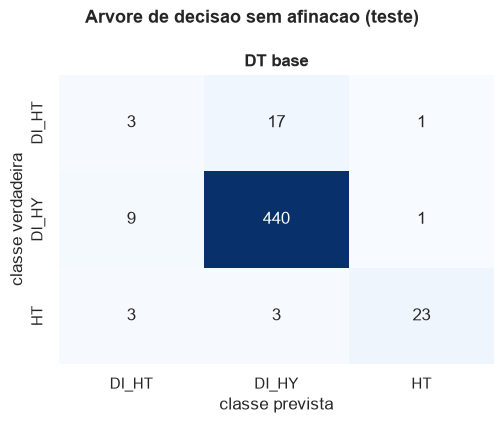

In [4]:
matrizes_confusao([prev_dt_base], ['DT base'], 'Arvore de decisao sem afinacao (teste)')

**Conclusões:** Os erros concentram-se na distinção entre `DI_HT` e `DI_HY`. A maior parte dos registos
`DI_HT` é classificada como `DI_HY`. É precisamente o par de classes que a análise exploratória
identificou como sobreposto: ambas têm HbA1c elevado (medianas 6.86 e 6.95) e só se distinguem
sobretudo pelos triglicerídeos. A classe `HT` é bem separada, com 23 de 29 casos corretos.

## 4. O compromisso viés-variância na árvore

Antes de afinar, convém **ver** o efeito do tamanho da árvore. Mede-se o F1
macro no treino e em validação cruzada para profundidades máximas de 1 a 20:

- com **pouca profundidade**, a árvore é demasiado simples e falha nos dois conjuntos: **viés alto**;
- com **muita profundidade**, acerta cada vez mais no treino, mas a validação deixa de acompanhar:
  **variância alta**.

A profundidade útil é aquela em que a curva de validação atinge o máximo antes de as duas curvas se
afastarem.

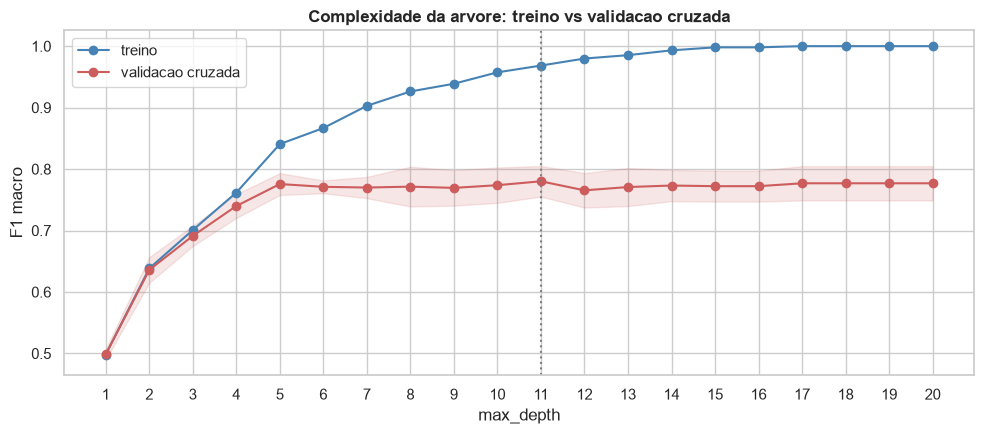

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
F1 treino,0.4980,0.6380,0.7010,0.7620,0.8410,0.8670,0.9030,0.9260,0.9390,0.9570,0.9680,0.9800,0.9850,0.9930,0.9980,0.9980,1.0000,1.0000,1.0000,1.0000
F1 CV,0.4990,0.6360,0.6910,0.7400,0.7760,0.7710,0.7700,0.7710,0.7690,0.7740,0.7800,0.7650,0.7710,0.7730,0.7720,0.7720,0.7770,0.7770,0.7770,0.7770
desvio CV,0.0090,0.0210,0.0160,0.0190,0.0180,0.0100,0.0170,0.0320,0.0290,0.0290,0.0250,0.0280,0.0310,0.0250,0.0250,0.0250,0.0280,0.0280,0.0280,0.0280


In [5]:
profundidades = np.arange(1, 21)
f1_treino, f1_val = validation_curve(
    DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    X_train, y_train, param_name='max_depth', param_range=profundidades,
    cv=cv, scoring='f1_macro', n_jobs=-1)

curva = pd.DataFrame({'max_depth': profundidades,
                      'F1 treino': f1_treino.mean(axis=1),
                      'F1 CV': f1_val.mean(axis=1), 'desvio CV': f1_val.std(axis=1)})

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(profundidades, curva['F1 treino'], 'o-', color='steelblue', label='treino')
ax.plot(profundidades, curva['F1 CV'], 'o-', color='indianred', label='validacao cruzada')
ax.fill_between(profundidades, curva['F1 CV'] - curva['desvio CV'],
                curva['F1 CV'] + curva['desvio CV'], color='indianred', alpha=0.15)
melhor = curva.loc[curva['F1 CV'].idxmax()]
ax.axvline(melhor['max_depth'], ls=':', color='grey')
ax.set_xlabel('max_depth'); ax.set_ylabel('F1 macro'); ax.set_xticks(profundidades)
ax.set_title('Complexidade da arvore: treino vs validacao cruzada', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()
curva.set_index('max_depth').T.round(3)

**Conclusões:** O gráfico mostra o compromisso viés-variância com clareza:

- **De 1 a 5 níveis, as duas curvas sobem juntas.** Com um só nível, o F1 é de 0.50 nos dois conjuntos,
  porque a árvore não tem complexidade suficiente para separar as três classes: é **viés**.
- **A partir de 5 níveis, as curvas separam-se.** O F1 de validação estabiliza em torno de **0.77 a
  0.78**, enquanto o de treino continua a subir até 1.0 aos 17 níveis. Esta subida já não corresponde
  a aprender padrões gerais, mas a **memorizar casos individuais**: é **variância**.

A partir dos 5 níveis a curva de validação é praticamente plana, com oscilações entre 0.765 e 0.780,
inferiores ao desvio entre partições (0.01 a 0.03). Escolher a profundidade "ótima" dentro deste
patamar seria escolher ruído. Isto mostra que a profundidade máxima, sozinha, não é suficiente para
controlar a árvore, e justifica afinar também `min_samples_leaf` e a poda `ccp_alpha`.

### Poda por custo-complexidade

A alternativa a limitar o crescimento é **deixar a árvore crescer e depois
podá-la**. O critério a minimizar é o erro da árvore mais **α vezes o número de folhas**. Com α = 0
obtém-se a árvore completa, e à medida que α aumenta, os ramos que menos contribuem para reduzir a
impureza são cortados.

O scikit-learn calcula, com `cost_complexity_pruning_path`, a sequência de valores de α em que a árvore
perde um ramo. Avaliam-se 40 desses valores por validação cruzada, registando o número de folhas e o
F1 macro.

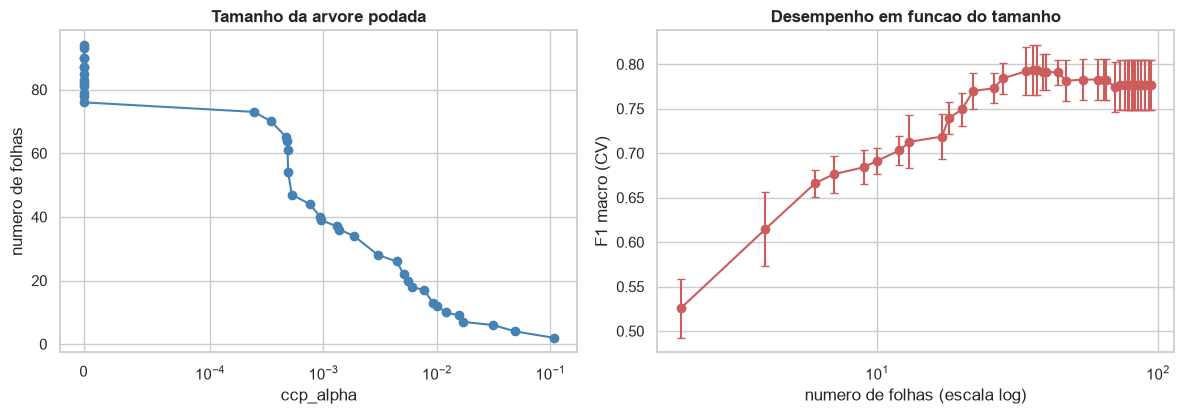

Arvore completa: alfa maximo util = 0.1066


,ccp_alpha,folhas,F1 CV,desvio CV
24,0.0014,36,0.7937,0.0278
23,0.0013,37,0.7937,0.0278
25,0.0019,34,0.7922,0.0270
20,0.0008,44,0.7911,0.0141
22,0.0010,39,0.7909,0.0202
21,0.0009,40,0.7909,0.0202
26,0.0030,28,0.7841,0.0171
15,0.0005,65,0.7828,0.0230


In [6]:
caminho_poda = DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)\
    .cost_complexity_pruning_path(X_train, y_train)
alfas = np.unique(np.quantile(caminho_poda.ccp_alphas[:-1], np.linspace(0, 1, 40)))

linhas_poda = []
for a in alfas:
    arvore = DecisionTreeClassifier(class_weight='balanced', ccp_alpha=a, random_state=RANDOM_STATE)
    pont = cross_val_score(arvore, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    folhas = arvore.fit(X_train, y_train).get_n_leaves()
    linhas_poda.append({'ccp_alpha': a, 'folhas': folhas, 'F1 CV': pont.mean(), 'desvio CV': pont.std()})
poda = pd.DataFrame(linhas_poda)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.plot(poda['ccp_alpha'], poda['folhas'], 'o-', color='steelblue')
ax1.set_xscale('symlog', linthresh=1e-4); ax1.set_xlabel('ccp_alpha'); ax1.set_ylabel('numero de folhas')
ax1.set_title('Tamanho da arvore podada', weight='bold')
ax2.errorbar(poda['folhas'], poda['F1 CV'], yerr=poda['desvio CV'], fmt='o-', color='indianred', capsize=3)
ax2.set_xscale('log'); ax2.set_xlabel('numero de folhas (escala log)'); ax2.set_ylabel('F1 macro (CV)')
ax2.set_title('Desempenho em funcao do tamanho', weight='bold')
plt.tight_layout(); plt.show()
print(f'Arvore completa: alfa maximo util = {caminho_poda.ccp_alphas[-2]:.4f}')
poda.sort_values('F1 CV', ascending=False).head(8).round(4)

**Conclusões:** A poda produz o resultado clássico:

- **À esquerda**, o número de folhas desce rapidamente à medida que α aumenta, de 94 na árvore
  completa até uma única folha (α acima de 0.1066).
- **À direita**, o F1 em validação cruzada é baixo para árvores muito pequenas, sobe até um máximo
  e volta a descer ligeiramente para árvores muito grandes.

O melhor resultado é **0.7937, com α igual a 0.0014 e 36 folhas**, contra 0.7768 da árvore completa.
**A árvore podada tem menos de 40% das folhas e é melhor**, porque os ramos removidos só capturavam
ruído do treino. A melhoria é contudo pequena face ao desvio entre partições (0.028).

Note-se que este valor de α fica entre dois pontos da grelha usada na versão inicial (0.001 e 0.005).
Por isso a grelha da secção seguinte inclui valores intermédios nesta região.

## 5. Afinação da árvore de decisão, 7.1(b)

A afinação usa `GridSearchCV`, com duas escolhas justificadas:

- **A métrica de seleção é o F1 macro, e não a accuracy.** Com classes tão
  desequilibradas, otimizar a accuracy levaria a escolher árvores que ignoram as classes minoritárias.
- **A validação cruzada é estratificada**, para que cada partição tenha `DI_HT` suficientes.

A grelha cruza os quatro hiperparâmetros que controlam a complexidade:

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `criterion` | gini, entropy | medida de impureza usada nas divisões |
| `max_depth` | 2 a 10, e sem limite | número máximo de perguntas seguidas |
| `min_samples_leaf` | 1 a 50 | número mínimo de registos numa folha |
| `ccp_alpha` | 0 a 0.01 | intensidade da poda, com resolução fina na região da secção 4 |

São 640 combinações, todas avaliadas **só no treino**.

In [7]:
grelha_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_leaf': [1, 5, 10, 20, 50],
    'ccp_alpha': [0.0, 0.0005, 0.001, 0.0015, 0.002, 0.003, 0.005, 0.01],
}
pesquisa_dt = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                           grelha_dt, scoring='f1_macro', cv=cv, n_jobs=-1)
pesquisa_dt.fit(X_train, y_train)

print('Combinacoes testadas:', len(pesquisa_dt.cv_results_['params']))
print('Melhores hiperparametros:', pesquisa_dt.best_params_)
print(f'F1 macro (CV) da melhor: {pesquisa_dt.best_score_:.4f}')

top_dt = pd.DataFrame(pesquisa_dt.cv_results_)
top_dt = top_dt[['param_criterion', 'param_max_depth', 'param_min_samples_leaf', 'param_ccp_alpha',
                 'mean_test_score', 'std_test_score', 'rank_test_score']]\
    .sort_values('rank_test_score').head(10)
top_dt

Combinacoes testadas: 640
Melhores hiperparametros: {'ccp_alpha': 0.0015, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1}
F1 macro (CV) da melhor: 0.7937


,param_criterion,param_max_depth,param_min_samples_leaf,param_ccp_alpha,mean_test_score,std_test_score,rank_test_score
275,gini,None,1,0.0015,0.7937,0.0278,1
355,gini,None,1,0.0020,0.7922,0.0270,2
350,gini,10,1,0.0020,0.7898,0.0275,3
270,gini,10,1,0.0015,0.7898,0.0275,3
195,gini,None,1,0.0010,0.7898,0.0196,5
345,gini,8,1,0.0020,0.7890,0.0237,6
265,gini,8,1,0.0015,0.7882,0.0269,7
190,gini,10,1,0.0010,0.7873,0.0199,8
425,gini,8,1,0.0030,0.7859,0.0163,9
186,gini,8,5,0.0010,0.7845,0.0164,10


**Conclusões:** A melhor combinação é `criterion='gini'`, sem limite de profundidade,
`min_samples_leaf=1` e **`ccp_alpha=0.0015`**, com F1 macro de **0.7937** em validação cruzada. É
praticamente o mesmo resultado da curva de poda, o que confirma a secção anterior de forma
independente.

Três observações sobre a tabela das dez melhores:

- **A poda faz o trabalho todo.** Na melhor combinação, `max_depth` e `min_samples_leaf` ficam nos
  valores mais permissivos. Quando há poda, limitar também o crescimento é redundante.
- **O Gini domina.** As dez melhores combinações usam todas Gini, mas as diferenças face à entropia
  são pequenas, o que é esperado, porque são medidas de impureza muito semelhantes.
- **Há um patamar, não um pico.** As dez melhores ficam entre 0.7845 e 0.7937, uma diferença de 0.009,
  muito inferior ao desvio entre partições, de cerca de 0.02 a 0.03. Várias árvores são
  estatisticamente equivalentes, e a escolhida é apenas a primeira desse patamar.

### Árvore base contra árvore afinada

O enunciado pede que se **justifique com evidência** se o modelo final deve generalizar a novos
pacientes. A evidência reúne-se em três frentes:

1. a **diferença entre treino e teste**, que mede o sobreajustamento;
2. a **concordância entre a validação cruzada e o teste**, que mostra se a estimativa feita no treino
   era fiável;
3. a **estabilidade** entre partições, avaliada a seguir com validação cruzada repetida.

In [8]:
dt_final = pesquisa_dt.best_estimator_
dt_final, prev_dt_final, linha_dt_final = avaliar(dt_final, 'DT afinada')

tabela_dt = pd.DataFrame([linha_dt_base, linha_dt_final]).set_index('modelo')
tabela_dt['gap treino-teste'] = tabela_dt['F1 macro (treino)'] - tabela_dt['F1 macro (teste)']
tabela_dt['profundidade'] = [dt_base.get_depth(), dt_final.get_depth()]
tabela_dt['folhas'] = [dt_base.get_n_leaves(), dt_final.get_n_leaves()]
tabela_dt.round(4)

,F1 macro (treino),F1 macro (CV),desvio (CV),F1 macro (teste),balanced acc (teste),accuracy (teste),recall DI_HT,recall DI_HY,recall HT,gap treino-teste,profundidade,folhas
modelo,,,,,,,,,,,,
DT base,1.0000,0.7768,0.0279,0.6619,0.6379,0.9320,0.1429,0.9778,0.7931,0.3381,15,94
DT afinada,0.8994,0.7937,0.0278,0.7541,0.7763,0.9380,0.5714,0.9644,0.7931,0.1453,10,35


**Conclusões:** A afinação melhora a árvore em todas as métricas relevantes:

| | DT base | DT afinada |
|---|---|---|
| Folhas / profundidade | 94 / 15 | **35 / 10** |
| F1 treino | 1.0000 | 0.8994 |
| F1 CV | 0.7768 | **0.7937** |
| F1 teste | 0.6619 | **0.7541** |
| Diferença treino-teste | 0.3381 | **0.1453** |
| Recall `DI_HT` | 0.1429 | **0.5714** |

- **O sobreajustamento cai para menos de metade.** A diferença treino-teste passa de 0.34 para 0.15.
  A árvore afinada já não decora o treino: o F1 no treino desce de 1.00 para 0.90, e é precisamente
  essa perda que melhora o teste.
- **A CV e o teste aproximam-se.** A diferença entre eles passa de 0.115 para 0.040. A estimativa feita
  no treino passou a ser mais fiável.
- **O ganho principal está na classe difícil.** O recall de `DI_HT` sobe de 3 para **12 das 21**
  ocorrências, e a balanced accuracy de 0.6379 para 0.7763.

A diferença treino-teste de 0.15 continua a não ser desprezável. Uma parte resulta do tamanho reduzido
das classes minoritárias no teste, mas outra parte é real: mesmo podada, a árvore mantém alguns ramos
que exploram ruído, como se verá na secção 6.

### Estabilidade da estimativa

Uma única validação cruzada depende da forma como os registos foram distribuídos pelas partições. Para
medir a **variância** de cada modelo, a validação de 5 partições é repetida 5 vezes com baralhamentos
diferentes, o que dá **25 valores de F1** por modelo. Uma caixa estreita indica um modelo estável.

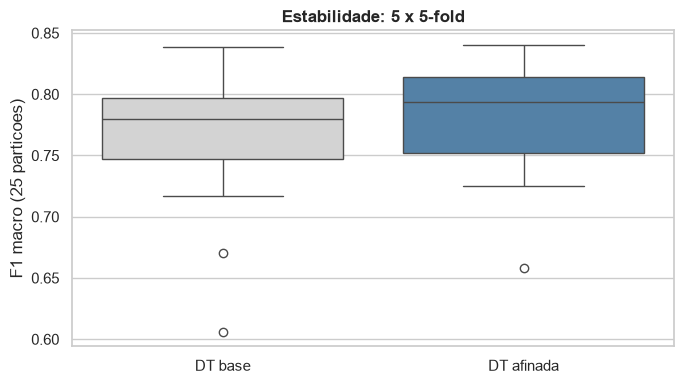

,DT base,DT afinada
mean,0.7679,0.7826
std,0.0502,0.0447
min,0.6058,0.6578
max,0.8388,0.8404


In [9]:
# Variancia da estimativa: 5 repeticoes de 5-fold = 25 valores de F1 por modelo
pont_rep = {nome: cross_val_score(m, X_train, y_train, cv=cv_repetida, scoring='f1_macro', n_jobs=-1)
            for nome, m in [('DT base', dt_base), ('DT afinada', dt_final)]}
pont_rep = pd.DataFrame(pont_rep)

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=pont_rep, ax=ax, palette=['lightgrey', 'steelblue'])
ax.set_ylabel('F1 macro (25 particoes)'); ax.set_title('Estabilidade: 5 x 5-fold', weight='bold')
plt.tight_layout(); plt.show()
pont_rep.describe().loc[['mean', 'std', 'min', 'max']].round(4)

**Conclusões:** A árvore afinada tem **média mais alta** (0.7826 contra 0.7679) e **menor dispersão**
(desvio de 0.0447 contra 0.0502). O pior caso melhora bastante, de 0.6058 para 0.6578, o que é
importante porque mostra que a afinação protege sobretudo contra as partições desfavoráveis.

A dispersão continua, ainda assim, elevada: entre o pior e o melhor caso há quase 0.20 de F1. Esta é a
**instabilidade característica de uma árvore isolada**, que é a sua fraqueza
principal, e é a motivação direta para a Random Forest.

Note-se que esta medida é ligeiramente otimista para a árvore afinada, porque os seus hiperparâmetros
foram escolhidos com uma das 25 partições. O efeito é pequeno porque as outras 20 são independentes da
afinação.

As duas matrizes de confusão, lado a lado, mostram onde a afinação mudou as previsões.

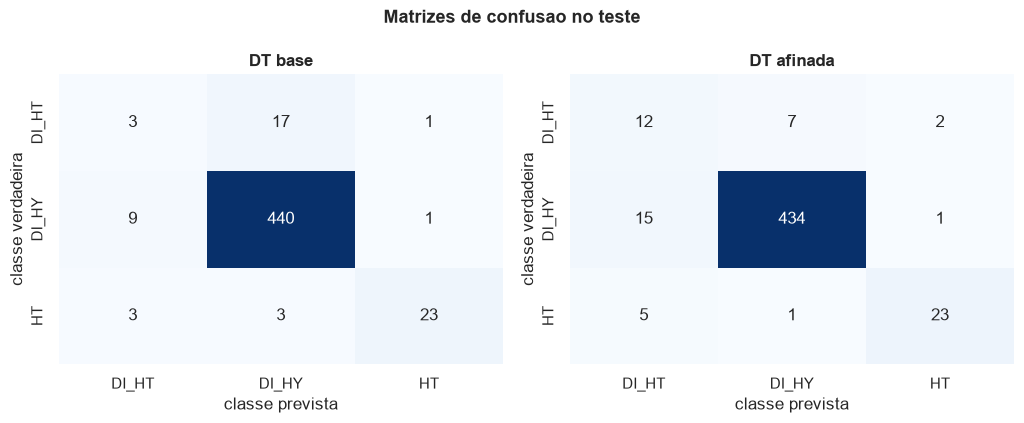

In [10]:
matrizes_confusao([prev_dt_base, prev_dt_final], ['DT base', 'DT afinada'],
                  'Matrizes de confusao no teste')

**Conclusões:** A mudança está quase toda na classe `DI_HT`: a árvore afinada deteta **12 das 21** em
vez de 3. O custo é um aumento dos registos `DI_HY` classificados como `DI_HT`, o que baixa a precisão
dessa classe para 0.3750: quando a árvore anuncia `DI_HT`, acerta em cerca de um caso em cada três. A
classe `HT` mantém 23 de 29 corretos nos dois modelos.

Com a compensação de classes, trocar falsos negativos por falsos positivos em `DI_HT` é o comportamento
esperado. Num contexto clínico de triagem, deixar escapar um doente com as duas doenças é normalmente
mais grave do que pedir exames a mais, mas essa ponderação depende de custos que o enunciado não
fornece.

## 6. Árvore final e regras de decisão, 7.1(c)

A árvore afinada tem 35 folhas, demasiadas para serem legíveis num só desenho. Desenham-se por isso os
**três primeiros níveis**, que contêm as decisões mais importantes porque afetam mais registos. A
árvore completa é apresentada a seguir em texto, com `export_text`.

Cada caixa mostra a pergunta, o Gini, a **proporção** de registos que lá chegam e a distribuição das
classes, já ponderada por `class_weight`. A cor indica a classe maioritária e a sua intensidade a
pureza do nó.

Arvore final: profundidade 10, 35 folhas. Desenham-se os tres primeiros niveis; a arvore completa segue em texto.


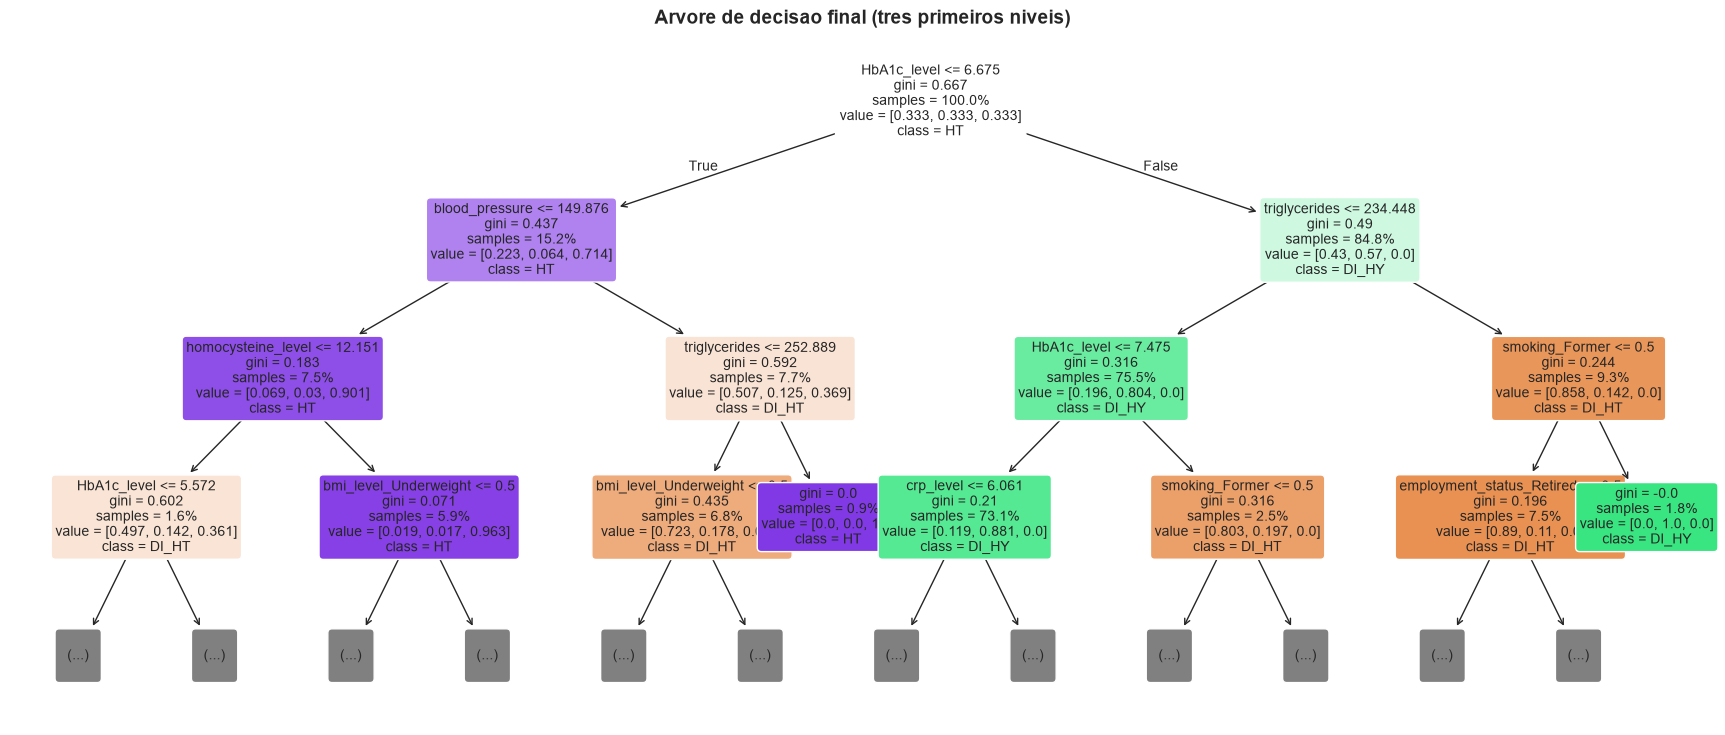

In [11]:
print(f'Arvore final: profundidade {dt_final.get_depth()}, {dt_final.get_n_leaves()} folhas. '
      'Desenham-se os tres primeiros niveis; a arvore completa segue em texto.')
plt.figure(figsize=(22, 9))
plot_tree(dt_final, feature_names=colunas, class_names=list(dt_final.classes_), max_depth=3,
          filled=True, rounded=True, fontsize=10, proportion=True, impurity=True)
plt.title('Arvore de decisao final (tres primeiros niveis)', fontsize=14, weight='bold')
plt.show()

**Conclusões:** A primeira divisão, sobre `HbA1c_level`, separa a árvore em dois grandes ramos:

- **à esquerda, HbA1c ≤ 6.67** (228 registos de treino), onde a classe `HT`, a única sem diabetes,
  representa 71% do peso ponderado;
- **à direita, HbA1c > 6.67** (1272 registos), onde **não há nenhum `HT`**: estão só os dois grupos
  com diabetes, `DI_HY` e `DI_HT`, que a árvore separa logo a seguir pelos **triglicerídeos** (limiar
  de cerca de 234).

Uma única pergunta isola, portanto, toda a classe `HT` de um dos lados.

As caixas mostram também que, com a ponderação das classes, os nós de topo parecem equilibrados,
apesar de 90% dos registos reais serem `DI_HY`.

A árvore completa em texto permite seguir todas as regras.

In [12]:
print(export_text(dt_final, feature_names=colunas, show_weights=False, decimals=2))

|--- HbA1c_level <= 6.67
|   |--- blood_pressure <= 149.88
|   |   |--- homocysteine_level <= 12.15
|   |   |   |--- HbA1c_level <= 5.57
|   |   |   |   |--- class: HT
|   |   |   |--- HbA1c_level >  5.57
|   |   |   |   |--- triglycerides <= 234.72
|   |   |   |   |   |--- class: DI_HY
|   |   |   |   |--- triglycerides >  234.72
|   |   |   |   |   |--- class: DI_HT
|   |   |--- homocysteine_level >  12.15
|   |   |   |--- bmi_level_Underweight <= 0.50
|   |   |   |   |--- HbA1c_level <= 6.52
|   |   |   |   |   |--- class: HT
|   |   |   |   |--- HbA1c_level >  6.52
|   |   |   |   |   |--- sugar_consumption_Low <= 0.50
|   |   |   |   |   |   |--- class: DI_HT
|   |   |   |   |   |--- sugar_consumption_Low >  0.50
|   |   |   |   |   |   |--- class: HT
|   |   |   |--- bmi_level_Underweight >  0.50
|   |   |   |   |--- class: DI_HY
|   |--- blood_pressure >  149.88
|   |   |--- triglycerides <= 252.89
|   |   |   |--- bmi_level_Underweight <= 0.50
|   |   |   |   |--- crp_level <= 

**Conclusões:** As regras principais podem ler-se diretamente:

| Regra | Classe |
|---|---|
| HbA1c ≤ 6.67 **e** HbA1c ≤ 5.57 (ramo com homocisteína ≤ 12.15) | `HT` |
| HbA1c ≤ 6.67 **e** triglicerídeos > 252.89 (ramo com pressão > 149.88) | `HT` |
| HbA1c > 6.67 **e** triglicerídeos ≤ 234.45 | sobretudo `DI_HY` |
| HbA1c > 6.67 **e** triglicerídeos > 234.45 | ramo onde se concentra `DI_HT`, que a árvore continua a dividir |

Na prática, a árvore aprendeu uma regra simples: **o HbA1c separa quem não tem diabetes (`HT`) dos
diabéticos, e os triglicerídeos separam, entre os diabéticos, quem tem também hipertensão (`DI_HT`)**.

Abaixo destas regras surgem cortes mais finos sobre `plasma_value`, `crp_level`, `smoking` ou
`education_level`, alguns com limiares quase iguais (por exemplo, `plasma_value <= 1.09` seguido de
outro corte em 1.09). Estes ramos afetam poucos registos e são os candidatos mais claros a **ruído
memorizado**, o que explica a diferença treino-teste ainda presente.

### Coerência com a análise exploratória

Para verificar se as regras fazem sentido, conta-se quantas vezes cada variável é usada nos cortes e
compara-se cada limiar com a mediana de cada classe no treino.

In [13]:
# Valores de referencia por classe, no treino, para confrontar com os cortes da arvore
cortes = pd.DataFrame({
    'variavel': [colunas[i] for i in dt_final.tree_.feature if i >= 0],
    'limiar': [t for i, t in zip(dt_final.tree_.feature, dt_final.tree_.threshold) if i >= 0]})
print('Variaveis usadas nos cortes (numero de nos):')
print(cortes['variavel'].value_counts().to_string())

usadas_num = [v for v in cortes['variavel'].unique() if v in var_num]
treino = X_train.assign(classe=y_train.values)
print('\nMediana por classe (treino) das variaveis numericas usadas:')
treino.groupby('classe')[usadas_num].median().round(2)

Variaveis usadas nos cortes (numero de nos):
variavel
HbA1c_level                  6
triglycerides                5
plasma_value                 5
bmi_level_Underweight        3
crp_level                    3
smoking_Former               3
blood_pressure               2
homocysteine_level           2
sugar_consumption_Low        1
age_level_Middle             1
smoking_Never                1
employment_status_Retired    1
education_level_Secondary    1

Mediana por classe (treino) das variaveis numericas usadas:


,HbA1c_level,blood_pressure,homocysteine_level,triglycerides,crp_level,plasma_value
classe,,,,,,
DI_HT,6.8600,149.9500,12.4400,246.2600,7.3300,1.2300
DI_HY,6.9500,149.9700,12.4200,150.0000,7.4600,1.2500
HT,5.4600,149.2500,12.5200,235.7800,7.4100,1.2500


**Conclusões:** **As regras principais são coerentes com a EDA**, mas os ramos inferiores não.

**Onde há coerência:**
- **`HbA1c_level`** é a variável mais usada (6 nós) e está na raiz. Na EDA era a variável com maior
  efeito sobre a classe, com **η² = 0.410**, e a única em que `HT` se destaca: mediana de 5.46 contra
  6.86 e 6.95. O limiar da raiz, 6.67, fica exatamente entre os dois grupos.
- **`triglycerides`** é a segunda variável mais usada (5 nós) e a segunda da EDA, com **η² = 0.105**. A
  mediana é 150.00 em `DI_HY` e 246.26 em `DI_HT`, e o limiar de 234 separa-as. É a única variável
  com capacidade para distinguir as duas classes com diabetes, o que a EDA já tinha indicado.

**Onde há incoerência:**
- **`plasma_value` é usada em 5 nós, tantos como os triglicerídeos**, mas a EDA não encontrou nela
  qualquer efeito (p = 0.611). As medianas por classe são praticamente iguais (1.23, 1.25 e 1.25).
  Os cortes sobre ela são ruído que a árvore aproveita em ramos pequenos.
- **`blood_pressure`** e **`homocysteine_level`** têm efeito significativo na EDA, mas muito fraco
  (η² inferior a 0.01), e as medianas por classe diferem menos de um ponto. A árvore usa-as apenas em
  ramos intermédios.

Este padrão é o esperado numa árvore isolada: as **duas primeiras perguntas** captam o sinal real,
e as restantes misturam algum sinal com ruído.

## 7. Random Forest sem afinação, 7.2(a)

A Random Forest base usa **500 árvores**, `bootstrap=True` e `oob_score=True`. O
número de variáveis candidatas por divisão fica no valor por omissão, `max_features='sqrt'`, que aqui
corresponde a **4 das 24 colunas**. Mantém-se `class_weight='balanced'` pela razão da secção 3.

In [14]:
rf_base = RandomForestClassifier(n_estimators=500, class_weight='balanced', oob_score=True,
                                 random_state=RANDOM_STATE, n_jobs=-1)
rf_base, prev_rf_base, linha_rf_base = avaliar(rf_base, 'RF base')

profs = [e.get_depth() for e in rf_base.estimators_]
print(f'Arvores: {len(rf_base.estimators_)} | max_features por divisao: sqrt({len(colunas)}) '
      f'= {int(np.sqrt(len(colunas)))} | profundidade media das arvores: {np.mean(profs):.1f}')
pd.DataFrame([linha_rf_base]).set_index('modelo').round(4)

Arvores: 500 | max_features por divisao: sqrt(24) = 4 | profundidade media das arvores: 14.2


,F1 macro (treino),F1 macro (CV),desvio (CV),F1 macro (teste),balanced acc (teste),accuracy (teste),recall DI_HT,recall DI_HY,recall HT
modelo,,,,,,,,,
RF base,0.9632,0.8472,0.0251,0.7960,0.8014,0.9540,0.4286,0.9756,1.0000


**Conclusões:** A Random Forest, **sem qualquer afinação, supera a melhor árvore afinada**:

| | DT afinada | RF base |
|---|---|---|
| F1 CV | 0.7937 | **0.8472** |
| F1 teste | 0.7541 | **0.7960** |
| Balanced accuracy | 0.7763 | **0.8014** |
| Recall `HT` | 0.7931 | **1.0000** |

É a demonstração prática da ideia central dos métodos de conjunto: **muitas árvores sobreajustadas, cada uma com
profundidade média de 14 níveis, produzem em conjunto um modelo melhor do que a melhor árvore
individual**. Cada árvore memoriza o seu próprio ruído, e a votação por maioria cancela-o.

A RF base deteta **todos os 29 casos `HT`** do teste, mas perde em `DI_HT`: o recall é 0.4286 (9 de
21), abaixo dos 12 de 21 da árvore afinada. Votar entre muitas árvores tende a favorecer as decisões
mais frequentes, o que prejudica a classe mais pequena.

A diferença entre a CV (0.8472) e o teste (0.7960) é semelhante à das árvores. Com tão poucos
registos minoritários no teste, a CV é a estimativa de referência.

### Porque não se usa o erro *out-of-bag*

O erro *out-of-bag* é, em princípio, uma forma gratuita de avaliar a Random Forest. Com
`oob_score=True`, contudo, o scikit-learn emite aqui o aviso *"Some inputs do not have OOB scores"*
(silenciado neste notebook pelo filtro de avisos), mesmo com 500 árvores. Em teoria, a probabilidade de um registo nunca ficar de fora em 500 amostras
*bootstrap* é praticamente nula, por isso vale a pena perceber o que se passa.

A explicação está na interação com `class_weight`. A partir da versão 1.8 do scikit-learn, quando há
pesos, **a amostra *bootstrap* é sorteada com probabilidade proporcional ao peso de cada registo**.
Com `class_weight='balanced'`, um registo `DI_HT` pesa 7.8125 e um `DI_HY` pesa 0.3709, ou seja, o
primeiro tem 21 vezes mais hipóteses de ser sorteado.

Para o verificar, reconstroem-se as 500 amostras *bootstrap* da RF base e conta-se quantas vezes cada
registo ficou de fora.

In [15]:
# Quantas vezes cada registo de treino ficou de fora (out-of-bag) nas 500 arvores?
fora = np.zeros(len(X_train), dtype=int)
pesos = np.ones(len(X_train))
for c, p in zip(*np.unique(y_train, return_counts=True)):
    pesos[y_train.values == c] = len(y_train) / (len(classes) * p)
for arvore in rf_base.estimators_:
    rng_arv = np.random.RandomState(arvore.random_state)
    escolhidos = rng_arv.choice(len(X_train), len(X_train), replace=True, p=pesos / pesos.sum())
    fora += np.bincount(escolhidos, minlength=len(X_train)) == 0

# Confirmacao com o proprio scikit-learn: registos sem nenhuma previsao OOB
sem_oob = rf_base.oob_decision_function_.sum(axis=1) == 0
diag = pd.DataFrame({'registos': y_train.value_counts(),
                     'peso por registo': pd.Series(pesos, index=y_train.index).groupby(y_train).first(),
                     'vezes fora, em 500 (media)': pd.Series(fora, index=y_train.index).groupby(y_train).mean(),
                     'registos sem previsao OOB': pd.Series(sem_oob, index=y_train.index).groupby(y_train).sum(),
                     'proporcao esperada em cada amostra':
                         pd.Series(pesos, index=y_train.index).groupby(y_train).sum() / pesos.sum()})
diag.loc[classes]

,registos,peso por registo,"vezes fora, em 500 (media)",registos sem previsao OOB,proporcao esperada em cada amostra
target_class,,,,,
DI_HT,64,7.8125,0.1875,52,0.3333
DI_HY,1348,0.3709,344.9651,0,0.3333
HT,88,5.6818,1.7727,13,0.3333


**Conclusões:** A verificação confirma a explicação:

| Classe | Registos | Vezes fora, em 500 árvores (média) | Registos sem previsão OOB |
|---|---|---|---|
| `DI_HT` | 64 | **0.19** | **52** |
| `HT` | 88 | 1.77 | 13 |
| `DI_HY` | 1348 | 345 | 0 |

Cada amostra *bootstrap* passa a ter, em média, **um terço de registos de cada classe**. Para reunir
cerca de 500 registos `DI_HT` a partir de apenas 64, cada um é sorteado várias vezes, e por isso quase
nunca fica de fora: **52 dos 64 nunca recebem uma previsão *out-of-bag***.

Isto tem duas consequências:

1. **Nesta versão, `class_weight='balanced'` numa Random Forest equivale a um *bootstrap* equilibrado.**
   Cada árvore treina com classes equilibradas, o que é uma forma de compensação ainda mais forte do
   que a simples ponderação usada na árvore isolada.
2. **O erro *out-of-bag* deixa de ser utilizável.** É calculado quase só com registos `DI_HY`, e os
   registos sem previsão são tratados como se tivessem probabilidade zero em todas as classes. Uma
   estimativa assim não diz nada sobre as classes minoritárias, que são precisamente as que interessam.

Por isso, **neste notebook a Random Forest é avaliada apenas por validação cruzada**, tal como a árvore
isolada, o que também torna as comparações entre os dois modelos mais justas.

## 8. Número de árvores: Random Forest contra bagging

O número de árvores não é um hiperparâmetro como os outros: **mais árvores não causam
sobreajustamento**, apenas estabilizam a votação, com mais custo computacional. Basta encontrar o
ponto a partir do qual acrescentar árvores deixa de mudar o resultado.

Mede-se o F1 macro em validação cruzada para 10 a 1000 árvores, comparando a **Random Forest**
(m = √p) com o **bagging** (m = p, `max_features=None`), as duas variantes descritas na secção 1. Usa-se
a validação cruzada em vez do erro *out-of-bag*, pela razão vista acima.

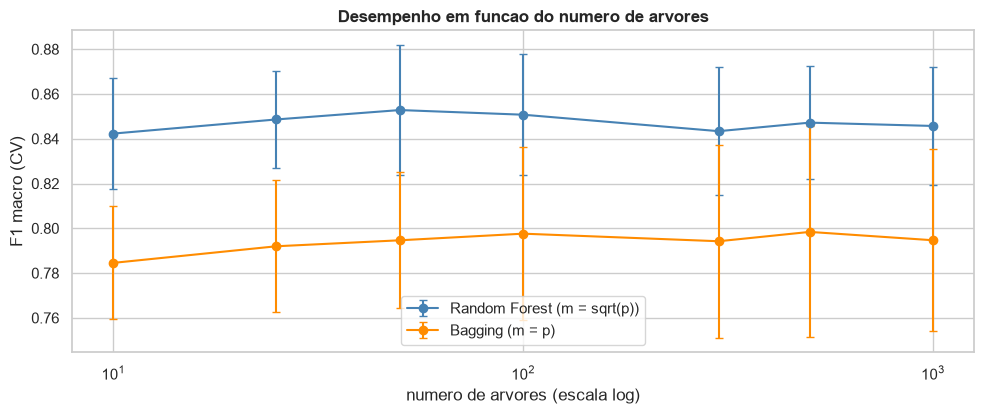

arvores,10,25,50,100,300,500,1000
metodo,,,,,,,
Bagging (m = p),0.7846,0.7920,0.7946,0.7976,0.7942,0.7984,0.7947
Random Forest (m = sqrt(p)),0.8423,0.8486,0.8528,0.8507,0.8434,0.8472,0.8457


In [16]:
numeros = [10, 25, 50, 100, 300, 500, 1000]
linhas_arv = []
for mf, rotulo in [('sqrt', 'Random Forest (m = sqrt(p))'), (None, 'Bagging (m = p)')]:
    for n in numeros:
        pont = cross_val_score(RandomForestClassifier(n_estimators=n, max_features=mf, class_weight='balanced',
                                                      random_state=RANDOM_STATE, n_jobs=-1),
                               X_train, y_train, cv=cv, scoring='f1_macro')
        linhas_arv.append({'metodo': rotulo, 'arvores': n, 'F1 CV': pont.mean(), 'desvio': pont.std()})
arv = pd.DataFrame(linhas_arv)

fig, ax = plt.subplots(figsize=(10, 4.3))
for (rotulo, grupo), cor in zip(arv.groupby('metodo', sort=False), ['steelblue', 'darkorange']):
    ax.errorbar(grupo['arvores'], grupo['F1 CV'], yerr=grupo['desvio'], fmt='o-', color=cor,
                capsize=3, label=rotulo)
ax.set_xscale('log'); ax.set_xlabel('numero de arvores (escala log)'); ax.set_ylabel('F1 macro (CV)')
ax.set_title('Desempenho em funcao do numero de arvores', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()
arv.pivot(index='metodo', columns='arvores', values='F1 CV').round(4)

**Conclusões:** Há duas leituras do gráfico:

- **O desempenho estabiliza muito cedo.** A partir de 50 árvores, o F1 da Random Forest oscila entre
  0.843 e 0.853, uma variação inferior ao desvio entre partições (cerca de 0.03). Mais árvores tornam
  a votação mais estável, mas não melhoram o modelo. Para a afinação usam-se **300 árvores**, e para o
  modelo final **500**, com margem de segurança e custo computacional aceitável.
- **A Random Forest é sempre superior ao bagging**, com cerca de 0.05 de vantagem em **todos** os
  números de árvores (por exemplo, 0.8472 contra 0.7984 com 500). A vantagem não resulta de usar mais
  ou menos árvores, mas de as árvores serem diferentes entre si. A secção seguinte confirma isto em
  toda a grelha de hiperparâmetros.

## 9. Afinação da Random Forest, 7.2(b)

A grelha cobre os três hiperparâmetros que controlam a complexidade de cada árvore e a correlação
entre elas:

| Hiperparâmetro | Valores | Justificação |
|---|---|---|
| `max_features` | sqrt, log2, 0.5, None | número de variáveis candidatas em cada divisão; `None` é o **bagging** |
| `max_depth` | 4 a 12, e sem limite | profundidade de cada árvore |
| `min_samples_leaf` | 1 a 20 | tamanho mínimo das folhas, para suavizar a votação |

O número de árvores é fixado em **300** durante a pesquisa, porque a secção anterior mostrou que o
desempenho já está estável a partir de 50, e passa a **500** no modelo final, por segurança. A
métrica é novamente o F1 macro, em validação cruzada estratificada no treino. São 80 combinações.

In [17]:
grelha_rf = {
    'max_features': ['sqrt', 'log2', 0.5, None],
    'max_depth': [None, 4, 6, 8, 12],
    'min_samples_leaf': [1, 3, 5, 10, 20],
}
pesquisa_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1),
    grelha_rf, scoring='f1_macro', cv=cv, n_jobs=-1)
pesquisa_rf.fit(X_train, y_train)

print('Combinacoes testadas:', len(pesquisa_rf.cv_results_['params']))
print('Melhores hiperparametros:', pesquisa_rf.best_params_)
print(f'F1 macro (CV) da melhor: {pesquisa_rf.best_score_:.4f}')

res_rf = pd.DataFrame(pesquisa_rf.cv_results_)
como_texto = lambda v: 'None' if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)
for col in ['param_max_features', 'param_max_depth']:
    res_rf[col] = res_rf[col].map(como_texto)
res_rf[['param_max_features', 'param_max_depth', 'param_min_samples_leaf',
        'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score').head(10)

Combinacoes testadas: 100
Melhores hiperparametros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3}
F1 macro (CV) da melhor: 0.8590


,param_max_features,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
1,sqrt,None,3,0.8590,0.0327,1
6,log2,None,3,0.8590,0.0327,1
81,sqrt,12,3,0.8590,0.0327,1
86,log2,12,3,0.8590,0.0327,1
66,log2,8,3,0.8540,0.0305,5
61,sqrt,8,3,0.8540,0.0305,5
45,log2,6,1,0.8494,0.0348,7
40,sqrt,6,1,0.8494,0.0348,7
60,sqrt,8,1,0.8470,0.0377,9
65,log2,8,1,0.8470,0.0377,9


**Conclusões:** A melhor combinação é **`max_features='sqrt'`, sem limite de profundidade e
`min_samples_leaf=3`**, com F1 macro de **0.8590** em validação cruzada, contra 0.8472 da RF base.

- **`sqrt` e `log2` dão resultados idênticos**, porque com 24 colunas ambas correspondem a 4 variáveis
  por divisão (√24 ≈ 4.9 e log₂24 ≈ 4.6, arredondados para baixo). São, na prática, a mesma
  configuração.
- **O único ajuste útil é `min_samples_leaf=3`.** Proibir folhas com um ou dois registos impede cada
  árvore de memorizar casos isolados. A profundidade só deixa de importar a partir de 12 níveis, porque
  as árvores raramente a ultrapassam.
- A melhoria face à RF base, de 0.012, fica abaixo do desvio entre partições (0.03), por isso
  **a afinação traz um ganho pequeno e não conclusivo**.

### A grelha completa: Random Forest contra bagging

Os mapas mostram o F1 de validação cruzada para todas as combinações, um painel por valor de
`max_features`. O painel da direita, `None`, corresponde ao **bagging**, e permite comparar
diretamente as duas abordagens nas mesmas condições.

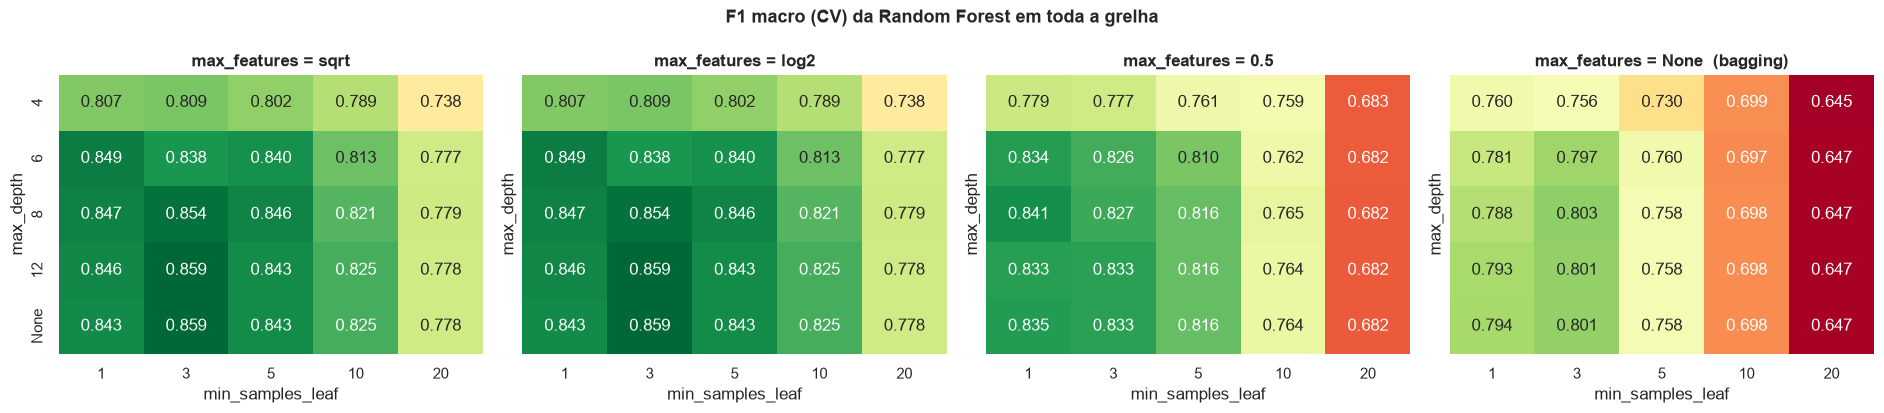

Melhor F1 (CV) para cada max_depth: {'12': 0.859, '4': 0.8092, '6': 0.8494, '8': 0.854, 'None': 0.859}
Melhor configuracao para cada valor de max_features:


,param_max_features,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
6,log2,None,3,0.8590,0.0327
1,sqrt,None,3,0.8590,0.0327
70,0.5,8,1,0.8412,0.0323
76,None,8,3,0.8026,0.0341


In [18]:
fig, eixos = plt.subplots(1, 4, figsize=(19, 4.2), sharey=True)
for eixo, mf in zip(eixos, ['sqrt', 'log2', '0.5', 'None']):
    tab = res_rf[res_rf['param_max_features'] == mf].pivot_table(
        index='param_max_depth', columns='param_min_samples_leaf', values='mean_test_score')
    tab = tab.reindex(['4', '6', '8', '12', 'None'])
    sns.heatmap(tab, annot=True, fmt='.3f', cmap='RdYlGn', vmin=res_rf['mean_test_score'].min(),
                vmax=res_rf['mean_test_score'].max(), cbar=False, ax=eixo)
    eixo.set_title(f'max_features = {mf}' + ('  (bagging)' if mf == 'None' else ''), weight='bold')
    eixo.set_xlabel('min_samples_leaf'); eixo.set_ylabel('max_depth')
fig.suptitle('F1 macro (CV) da Random Forest em toda a grelha', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

print('Melhor F1 (CV) para cada max_depth:',
      res_rf.groupby('param_max_depth')['mean_test_score'].max().round(4).to_dict())
print('Melhor configuracao para cada valor de max_features:')
res_rf.loc[res_rf.groupby('param_max_features')['mean_test_score'].idxmax(),
           ['param_max_features', 'param_max_depth', 'param_min_samples_leaf',
            'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False)

**Conclusões:** **A Random Forest é claramente superior ao bagging neste problema.**

| `max_features` | Variáveis por divisão | Melhor F1 (CV) |
|---|---|---|
| sqrt / log2 | 4 | **0.8590** |
| 0.5 | 12 | 0.8412 |
| None (bagging) | 24 | 0.8026 |

O desempenho **desce à medida que se permitem mais variáveis em cada divisão**, e o bagging fica 0.056
abaixo da Random Forest, quase duas vezes o desvio entre partições.

É exatamente o mecanismo descrito na secção 1. Neste conjunto de dados há uma variável dominante, o
**HbA1c**, com η² = 0.410, quatro vezes mais do que a segunda. No bagging, todas as árvores a escolhem
para a primeira divisão, e por isso ficam **muito parecidas entre si**. A média de modelos
correlacionados reduz pouco a variância. Ao restringir cada divisão a 4 variáveis sorteadas, a Random
Forest obriga muitas árvores a começar por outras variáveis, como os triglicerídeos. As árvores ficam
**descorrelacionadas**, e a votação torna-se muito mais eficaz.

Nos painéis também se vê que **árvores rasas são piores em qualquer configuração**: com `max_depth=4`,
o melhor F1 é 0.8092, contra 0.8590 sem limite de profundidade. A Random Forest precisa de árvores profundas, com pouco viés, porque é a
votação que trata da variância.

### Comparação dos quatro modelos

A Random Forest final é treinada com os hiperparâmetros escolhidos e 500 árvores. A tabela junta os
quatro modelos do notebook, que é a comparação pedida no ponto 7.2(b).

In [19]:
rf_final = clone(pesquisa_rf.best_estimator_).set_params(n_estimators=500, n_jobs=-1)
rf_final, prev_rf_final, linha_rf_final = avaliar(rf_final, 'RF afinada')

tabela = pd.DataFrame([linha_dt_base, linha_dt_final, linha_rf_base, linha_rf_final]).set_index('modelo')
tabela['gap treino-teste'] = tabela['F1 macro (treino)'] - tabela['F1 macro (teste)']
tabela.round(4)

,F1 macro (treino),F1 macro (CV),desvio (CV),F1 macro (teste),balanced acc (teste),accuracy (teste),recall DI_HT,recall DI_HY,recall HT,gap treino-teste
modelo,,,,,,,,,,
DT base,1.0000,0.7768,0.0279,0.6619,0.6379,0.9320,0.1429,0.9778,0.7931,0.3381
DT afinada,0.8994,0.7937,0.0278,0.7541,0.7763,0.9380,0.5714,0.9644,0.7931,0.1453
RF base,0.9632,0.8472,0.0251,0.7960,0.8014,0.9540,0.4286,0.9756,1.0000,0.1672
RF afinada,0.8974,0.8555,0.0292,0.7867,0.8165,0.9540,0.4762,0.9733,1.0000,0.1108


**Conclusões:**

| Modelo | F1 CV | F1 teste | Balanced acc | Recall `DI_HT` | Diferença treino-teste |
|---|---|---|---|---|---|
| DT base | 0.7768 | 0.6619 | 0.6379 | 0.1429 | 0.3381 |
| DT afinada | 0.7937 | 0.7541 | 0.7763 | **0.5714** | 0.1453 |
| RF base | 0.8472 | **0.7960** | 0.8014 | 0.4286 | 0.1672 |
| RF afinada | **0.8555** | 0.7867 | **0.8165** | 0.4762 | **0.1108** |

- **As duas Random Forest são melhores do que as duas árvores** em F1 de validação cruzada (cerca de
  +0.06), em F1 de teste e em balanced accuracy.
- **A RF afinada é a que menos sobreajusta.** A diferença treino-teste de 0.1108 é a mais pequena dos
  quatro modelos, graças a `min_samples_leaf=3`.
- **No teste, a RF base e a afinada estão empatadas.** O F1 da afinada é 0.009 inferior, mas a sua
  balanced accuracy é 0.015 superior, e deteta mais um caso `DI_HT`. Com 21 registos nessa classe,
  estas diferenças correspondem a um ou dois doentes e não permitem preferir uma à outra com base no
  teste.

**A escolha final é a RF afinada**, porque tem o melhor F1 de validação cruzada (o critério definido
antes de olhar para o teste), a melhor balanced accuracy e o menor sobreajustamento.


### Variância das estimativas

A principal promessa da Random Forest é **reduzir a variância** de uma árvore isolada. Repete-se por
isso a validação cruzada 5 × 5 da secção 5 para os dois modelos de Random Forest.

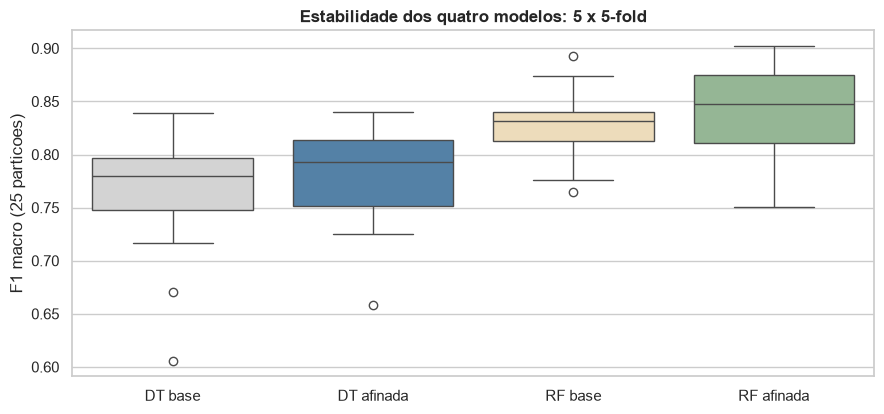

,DT base,DT afinada,RF base,RF afinada
mean,0.7679,0.7826,0.8279,0.8419
std,0.0502,0.0447,0.0301,0.0388
min,0.6058,0.6578,0.7649,0.7502
max,0.8388,0.8404,0.8925,0.9020


In [20]:
for nome, m in [('RF base', rf_base), ('RF afinada', rf_final)]:
    pont_rep[nome] = cross_val_score(clone(m).set_params(oob_score=False), X_train, y_train,
                                     cv=cv_repetida, scoring='f1_macro', n_jobs=-1)

fig, ax = plt.subplots(figsize=(9, 4.3))
sns.boxplot(data=pont_rep, ax=ax, palette=['lightgrey', 'steelblue', 'wheat', 'darkseagreen'])
ax.set_ylabel('F1 macro (25 particoes)'); ax.set_title('Estabilidade dos quatro modelos: 5 x 5-fold', weight='bold')
plt.tight_layout(); plt.show()
pont_rep.describe().loc[['mean', 'std', 'min', 'max']].round(4)

**Conclusões:** A Random Forest **cumpre a promessa de reduzir a variância**:

| | DT base | DT afinada | RF base | RF afinada |
|---|---|---|---|---|
| Média (25 partições) | 0.7679 | 0.7826 | 0.8279 | **0.8419** |
| Desvio | 0.0502 | 0.0447 | **0.0301** | 0.0388 |
| Pior partição | 0.6058 | 0.6578 | **0.7649** | 0.7502 |

As caixas das Random Forest estão **mais acima e são mais estreitas**. O pior resultado das Random
Forest, entre 0.75 e 0.76, fica perto da **média** da árvore afinada, 0.78. Em nenhuma partição uma
árvore isolada se aproxima do melhor resultado da Random Forest.

A RF afinada tem média mais alta mas desvio um pouco maior do que a base. Com 25 partições, a
diferença entre as médias (0.014) é da ordem dos desvios, o que confirma que as duas Random Forest
são praticamente equivalentes.

**Generalização a novos pacientes.** Há três sinais de que a RF afinada deve generalizar:
1. a validação cruzada (0.8555), a validação repetida (0.8419) e o teste (0.7867) dão valores próximos;
2. a diferença treino-teste é a menor dos quatro modelos;
3. a variância entre partições é baixa.

A ressalva é que o teste fica sistematicamente abaixo da validação cruzada em todos os modelos, cerca
de 0.04 a 0.07. Com só 21 `DI_HT` no teste, parte desta diferença é acaso, mas é prudente esperar
**um F1 em novos pacientes da ordem de 0.79, e não de 0.86**.

As matrizes de confusão da árvore afinada e das duas Random Forest mostram como cada modelo erra, e a
tabela de precisão completa o recall já apresentado.

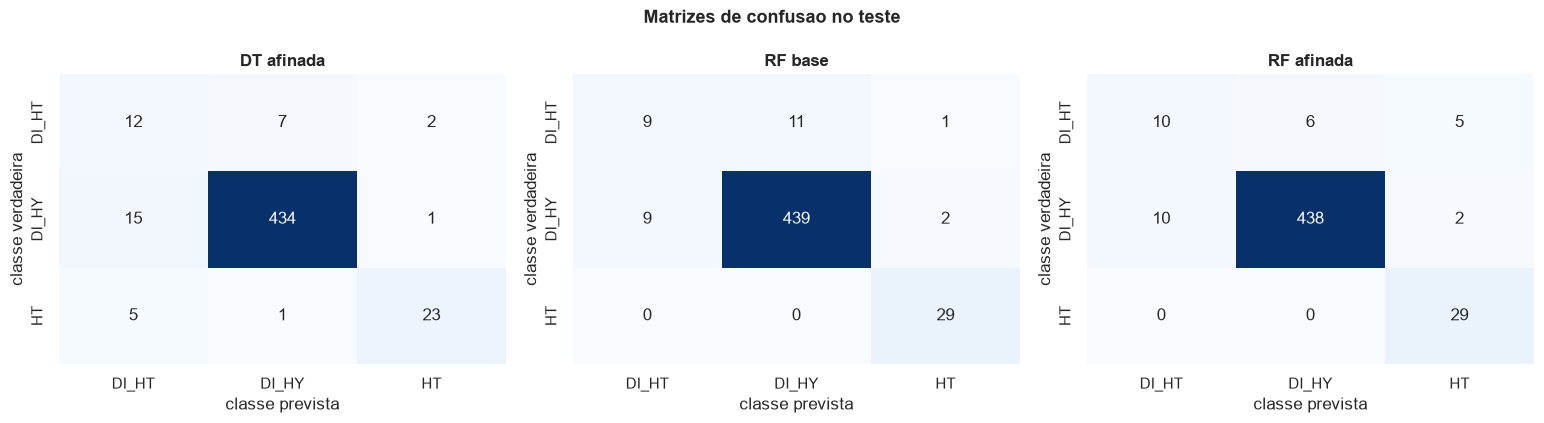

Precisao por classe no teste:


,DT afinada,RF base,RF afinada
DI_HT,0.3750,0.5000,0.5000
DI_HY,0.9819,0.9756,0.9865
HT,0.8846,0.9062,0.8056


In [21]:
matrizes_confusao([prev_dt_final, prev_rf_base, prev_rf_final], ['DT afinada', 'RF base', 'RF afinada'],
                  'Matrizes de confusao no teste')
print('Precisao por classe no teste:')
pd.DataFrame({nome: precision_score(y_test, p, average=None, labels=classes, zero_division=0)
              for nome, p in [('DT afinada', prev_dt_final), ('RF base', prev_rf_base),
                              ('RF afinada', prev_rf_final)]}, index=classes).round(4)

**Conclusões:** Os três modelos **erram nos mesmos sítios**, nomeadamente na separação entre `DI_HT` e
`DI_HY`, mas com perfis diferentes:

- **A árvore afinada** deteta mais `DI_HT` (12 de 21), mas à custa de muitos falsos alarmes:
  precisão de **0.3750**.
- **As Random Forest** detetam menos (9 e 10 de 21), mas quando anunciam `DI_HT` acertam em **metade
  dos casos**, com precisão de 0.5000. Na classe `HT`, detetam os 29 casos.

A Random Forest é, portanto, um classificador **mais equilibrado**: o melhor F1 resulta de um melhor
compromisso entre recall e precisão, e não de maximizar apenas uma delas. A sobreposição entre `DI_HT`
e `DI_HY` continua a ser o limite do problema, qualquer que seja o modelo.

## 10. Importância das variáveis, 7.2(c)

Usam-se dois métodos complementares, porque cada um tem uma limitação conhecida.

**1. MDI (*mean decrease in impurity*).** É o `feature_importances_` do scikit-learn. Para cada
variável, soma-se a **redução do Gini** em todas as divisões que a usam, ponderada pelo número de
registos que passam nesse nó, e faz-se a média sobre as 500 árvores. Os valores são normalizados para
somar 1. Calcula-se **no treino**, e por isso favorece as variáveis numéricas com muitos valores
diferentes: têm mais limiares possíveis, logo mais oportunidades de reduzir a impureza, mesmo que seja
por acaso.

**2. Importância por permutação.** Para cada variável, **baralham-se os seus valores no teste** e mede-se
quanto o F1 macro cai. Se a variável não importa, baralhá-la não muda nada. Este método mede o efeito
real nas previsões em dados novos, e não sofre do enviesamento do MDI. Repete-se 30 vezes por
variável.

Nos dois casos, as colunas binárias de cada variável categórica são **agrupadas**: o MDI é somado e, na
permutação, todas as colunas da variável são baralhadas em conjunto. Isto permite comparar 15 variáveis
originais, e não 24 colunas.

In [22]:
# 1) MDI: reducao media de impureza, somada pelas colunas binarias de cada variavel
mdi = pd.Series(rf_final.feature_importances_, index=colunas).groupby(variavel_de).sum()

# 2) Permutacao ao nivel da variavel: baralham-se juntas todas as colunas de cada variavel
rng = np.random.default_rng(RANDOM_STATE)
base_f1 = f1_score(y_test, rf_final.predict(X_test), average='macro')
REPETICOES = 30
perm = {}
for v in VARIAVEIS:
    cols_v = [c for c in colunas if variavel_de(c) == v]
    quedas = []
    for _ in range(REPETICOES):
        X_perm = X_test.copy()
        X_perm[cols_v] = X_test[cols_v].values[rng.permutation(len(X_test))]
        quedas.append(base_f1 - f1_score(y_test, rf_final.predict(X_perm), average='macro'))
    perm[v] = (np.mean(quedas), np.std(quedas))
perm = pd.DataFrame(perm, index=['queda F1 (media)', 'queda F1 (desvio)']).T

importancias = pd.DataFrame({'MDI': mdi}).join(perm)
importancias['tipo'] = ['numerica' if v in var_num else 'categorica' for v in importancias.index]
importancias = importancias.sort_values('MDI', ascending=False)
importancias.insert(0, 'posicao MDI', range(1, len(importancias) + 1))
importancias['posicao permutacao'] = importancias['queda F1 (media)'].rank(ascending=False).astype(int)
importancias.round(4)

,posicao MDI,MDI,queda F1 (media),queda F1 (desvio),tipo,posicao permutacao
HbA1c_level,1,0.2741,0.2786,0.0240,numerica,1
triglycerides,2,0.1907,0.0853,0.0279,numerica,2
blood_pressure,3,0.1286,0.0142,0.0216,numerica,4
homocysteine_level,4,0.0838,0.0041,0.0151,numerica,7
crp_level,5,0.0672,-0.0023,0.0126,numerica,12
bmi_level,6,0.0453,0.0241,0.0146,categorica,3
plasma_value,7,0.0284,0.0067,0.0071,numerica,5
smoking,8,0.0284,-0.0012,0.0083,categorica,9
employment_status,9,0.0277,-0.0012,0.0102,categorica,10
age_level,10,0.0261,-0.0020,0.0111,categorica,11


**Conclusões:** **Lista ordenada da importância das variáveis na RF final (MDI):**

| Posição | Variável | MDI | Queda F1 (permutação) |
|---|---|---|---|
| 1 | `HbA1c_level` | **0.2741** | **0.2786** |
| 2 | `triglycerides` | **0.1907** | **0.0853** |
| 3 | `blood_pressure` | 0.1286 | 0.0142 |
| 4 | `homocysteine_level` | 0.0838 | 0.0041 |
| 5 | `crp_level` | 0.0672 | −0.0023 |
| 6 | `bmi_level` | 0.0453 | 0.0241 |
| 7 | `plasma_value` | 0.0284 | 0.0067 |
| 8 a 15 | restantes categóricas | 0.013 a 0.028 | entre −0.005 e 0.006 |

**Os dois métodos concordam no topo.** O **HbA1c** é de longe a variável mais importante: sozinho
responde por 27% da redução de impureza, e baralhá-lo faz o F1 cair 0.28. Os **triglicerídeos** são o
segundo, com uma queda de 0.085.

**Os dois métodos discordam no resto, e a discordância é explicável:**
- **As cinco primeiras posições do MDI são todas numéricas.** `blood_pressure`, `homocysteine_level` e
  `crp_level` somam 28% do MDI, mas baralhá-las no teste quase não muda o F1 (quedas entre −0.002 e
  0.014, dentro do desvio). É o **enviesamento do MDI** descrito acima: estas variáveis contínuas
  oferecem centenas de limiares, e as árvores usam-nas para separar ruído do treino.
- **`bmi_level` sobe de 6.º para 3.º lugar na permutação.** É uma variável categórica com 4 níveis,
  prejudicada no MDI, mas com efeito real em dados novos.
- Várias variáveis têm **queda negativa**: baralhá-las melhora ligeiramente o F1. Isto indica que não
  contribuem para o modelo, e que o modelo funcionaria igualmente bem sem elas.

A conclusão é que **a Random Forest se apoia essencialmente em três variáveis**, `HbA1c_level`,
`triglycerides` e `bmi_level`, e que a ordem do MDI a partir da 3.ª posição não deve ser interpretada
como importância clínica.

Os dois métodos lado a lado, com as variáveis pela ordem do MDI. A cor distingue numéricas e
categóricas, para tornar visível o enviesamento do MDI.

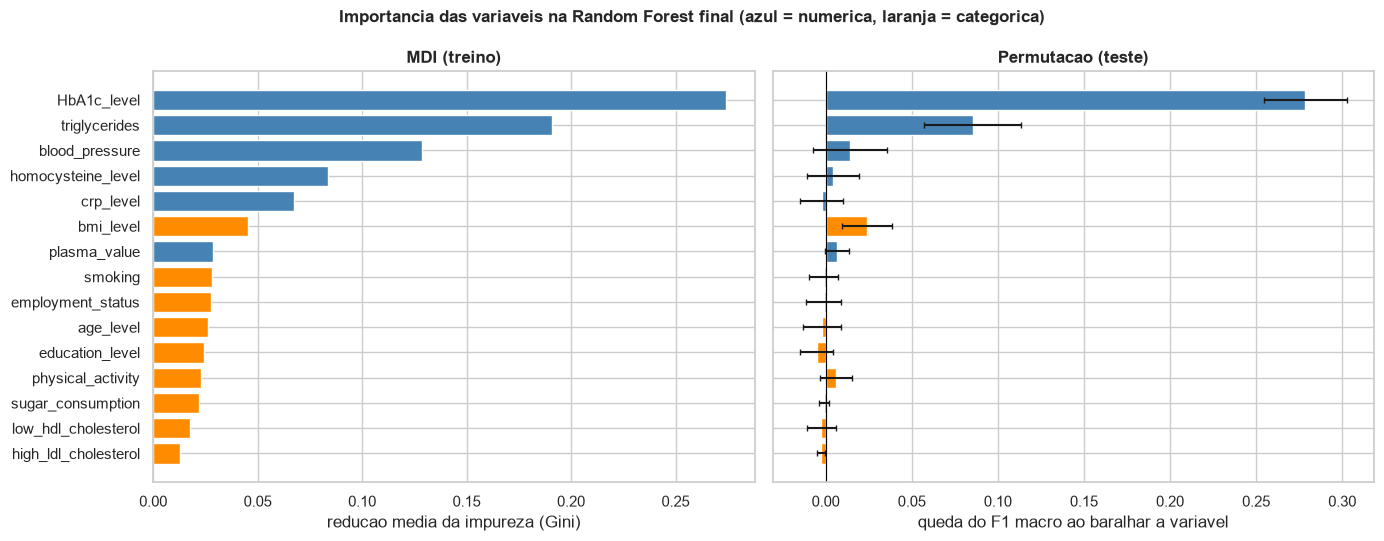

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
ordem = importancias.index[::-1]
cores = ['steelblue' if importancias.loc[v, 'tipo'] == 'numerica' else 'darkorange' for v in ordem]
ax1.barh(ordem, importancias.loc[ordem, 'MDI'], color=cores)
ax1.set_xlabel('reducao media da impureza (Gini)'); ax1.set_title('MDI (treino)', weight='bold')
ax2.barh(ordem, importancias.loc[ordem, 'queda F1 (media)'], xerr=importancias.loc[ordem, 'queda F1 (desvio)'],
         color=cores, capsize=2)
ax2.axvline(0, color='black', lw=0.8)
ax2.set_xlabel('queda do F1 macro ao baralhar a variavel'); ax2.set_title('Permutacao (teste)', weight='bold')
fig.suptitle('Importancia das variaveis na Random Forest final (azul = numerica, laranja = categorica)',
             fontsize=12, weight='bold')
plt.tight_layout(); plt.show()

**Conclusões:** O gráfico torna o enviesamento visível. No painel do MDI, as **barras azuis
(numéricas) ocupam todo o topo**, e as laranja (categóricas) têm todas valores parecidos e baixos. No
painel da permutação, só três barras se destacam claramente de zero, HbA1c, triglicerídeos e
`bmi_level`, e a categórica `bmi_level` aparece à frente de três numéricas. As barras de erro mostram
que, abaixo do terceiro lugar, as quedas são indistinguíveis de zero.

## 11. Comparação com a EDA e com Ridge e Lasso, 7.2(d)

Junta-se numa tabela, para cada uma das 15 variáveis:

- **a posição na Random Forest**, pelos dois métodos;
- **o efeito na EDA**: η² para as numéricas, com o p-value do Kruskal-Wallis, e V de Cramér para as
  categóricas, com o p-value do χ². São recalculados aqui nos 2000 registos, com os mesmos métodos da
  EDA;
- **o maior |coeficiente| no Ridge e no Lasso**, refeitos com os valores de `C` escolhidos na Tarefa 5
  para o conjunto de 15 (1.9745 e 4.3288), com os dados padronizados;
- **se a variável sobrevive** ao corte mais agressivo do Lasso, o conjunto de 11.

Como o η² e o V de Cramér não são comparáveis entre si, a ordenação da EDA é feita pelo **p-value**,
que é a única medida comum aos dois testes.

In [24]:
# EDA: eta-quadrado do Kruskal-Wallis (numericas) e V de Cramer (categoricas), nos 2000 registos
def eta2_kruskal(v):
    """eta-quadrado (variancia entre classes / variancia total), como na EDA, e p do Kruskal-Wallis."""
    grupos = [df.loc[df[TARGET_CLS] == c, v] for c in classes]
    media = df[v].mean()
    entre = sum(len(g) * (g.mean() - media) ** 2 for g in grupos)
    return entre / ((df[v] - media) ** 2).sum(), kruskal(*grupos).pvalue

def v_cramer(v):
    tab = pd.crosstab(df[v], df[TARGET_CLS])
    chi2, p, _, _ = chi2_contingency(tab)
    return np.sqrt(chi2 / (len(df) * (min(tab.shape) - 1))), p

eda = {v: (eta2_kruskal(v) if v in var_num else v_cramer(v)) for v in VARIAVEIS}

# Tarefa 5: Ridge e Lasso no conjunto de 15, com os C escolhidos por CV nessa tarefa
escala = StandardScaler().fit(X_train)
coefs = {}
for nome, ratio, C in [('Ridge', 0.0, 1.9745), ('Lasso', 1.0, 4.3288)]:
    m = LogisticRegression(solver='saga', l1_ratio=ratio, C=C, max_iter=10000,
                           random_state=RANDOM_STATE).fit(escala.transform(X_train), y_train)
    coefs[nome] = pd.Series(np.abs(m.coef_).max(axis=0), index=colunas).groupby(variavel_de).max()

CONJUNTO_11 = ['HbA1c_level', 'age', 'age_level', 'blood_pressure', 'bmi', 'bmi_level', 'crp_level',
               'employment_status', 'low_hdl_cholesterol', 'smoking', 'triglycerides']

cruz = pd.DataFrame({
    'posicao RF (MDI)': importancias['posicao MDI'],
    'posicao RF (perm.)': importancias['posicao permutacao'],
    'efeito EDA': {v: e[0] for v, e in eda.items()},
    'medida EDA': {v: ('eta2' if v in var_num else 'V Cramer') for v in VARIAVEIS},
    'p-value EDA': {v: e[1] for v, e in eda.items()},
    '|coef| Ridge': coefs['Ridge'],
    '|coef| Lasso': coefs['Lasso'],
    'no conjunto de 11': {v: ('sim' if v in CONJUNTO_11 else 'nao') for v in VARIAVEIS},
}).sort_values('posicao RF (MDI)')
cruz['posicao Lasso'] = cruz['|coef| Lasso'].rank(ascending=False).astype(int)
cruz['posicao EDA (p)'] = cruz['p-value EDA'].rank().astype(int)
cruz.round(4)

,posicao RF (MDI),posicao RF (perm.),efeito EDA,medida EDA,p-value EDA,|coef| Ridge,|coef| Lasso,no conjunto de 11,posicao Lasso,posicao EDA (p)
HbA1c_level,1,1,0.4100,eta2,0.0000,2.2481,3.4186,sim,1,1
triglycerides,2,2,0.1050,eta2,0.0000,0.6975,0.9935,sim,3,2
blood_pressure,3,4,0.0087,eta2,0.0000,0.1459,0.1527,sim,12,3
homocysteine_level,4,7,0.0036,eta2,0.0000,0.1085,0.1202,nao,14,7
crp_level,5,12,0.0097,eta2,0.2979,0.1773,0.2266,sim,11,14
bmi_level,6,3,0.1078,V Cramer,0.0000,1.0535,1.8010,sim,2,5
plasma_value,7,5,0.0005,eta2,0.6108,0.1507,0.1517,nao,13,15
smoking,8,9,0.0578,V Cramer,0.0096,0.2180,0.2614,sim,10,12
employment_status,9,10,0.0586,V Cramer,0.0081,0.2929,0.3697,sim,9,11
age_level,10,11,0.1126,V Cramer,0.0000,0.4640,0.5539,sim,6,4


**Conclusões:** A tabela mostra **concordância total no topo e desacordo sistemático no meio**.

**Onde os três métodos concordam:**
- **`HbA1c_level` é a primeira em todos os critérios**: posição 1 na RF, maior η² na EDA (0.410) e
  maior coeficiente no Ridge e no Lasso (3.42).
- **`triglycerides`** é 2.ª na RF, 2.ª na EDA e 3.ª no Lasso.
- **`bmi_level`** é 3.ª na permutação, 2.ª no Lasso e tem um dos maiores V de Cramér (0.108).

As três abordagens, que se baseiam em princípios completamente diferentes (testes estatísticos
univariados, um modelo linear penalizado e um conjunto de árvores), **identificam as mesmas três
variáveis**. É a evidência mais forte de que estas variáveis têm sinal real.

**Onde discordam:**

| Variável | RF (MDI) | EDA | Lasso | Explicação |
|---|---|---|---|---|
| `blood_pressure`, `homocysteine_level` | 3.ª e 4.ª | significativas, η² < 0.01 | 12.ª e 14.ª | numéricas com efeito real mas fraquíssimo: o MDI sobrevaloriza-as, o Lasso quase as anula |
| `crp_level`, `plasma_value` | 5.ª e 7.ª | **não significativas** (p = 0.298 e 0.611) | 11.ª e 13.ª | ruído que o MDI premeia por serem contínuas; a permutação coloca-as em 12.ª e 5.ª, com quedas próximas de zero |
| `physical_activity`, `education_level` | 12.ª e 11.ª | significativas (V ≈ 0.06 a 0.07) | **4.ª e 5.ª** | categóricas com efeito fraco mas consistente, que o modelo linear aproveita e o MDI desvaloriza |
| `low_hdl_cholesterol` | 14.ª | **maior V de Cramér** (0.125) | **15.ª** | ver abaixo |

Três razões explicam estas diferenças:

1. **O enviesamento do MDI** a favor das variáveis contínuas, já discutido na secção 10.
2. **Lineariedade.** O Lasso só capta efeitos lineares e aditivos, enquanto as árvores captam limiares
   e interações. Uma categórica com efeito pequeno mas consistente, como `physical_activity`, recebe
   um coeficiente claro no Lasso. Na RF, as árvores raramente a escolhem, porque as numéricas
   oferecem sempre uma divisão ligeiramente melhor no treino.
3. **Redundância.** `low_hdl_cholesterol` tem a maior associação da EDA, mas é a última no Lasso e
   14.ª na RF. Medido isoladamente, o efeito é real; dentro de um modelo, a informação que transporta
   é já dada por outras variáveis, e o modelo não precisa dela. Um teste univariado não consegue
   detetar esta redundância.

Para resumir a concordância num número, calcula-se a correlação de Spearman entre as quatro
ordenações. Vale 1 quando duas ordenações são idênticas e 0 quando não têm relação.

In [25]:
posicoes = cruz[['posicao RF (MDI)', 'posicao RF (perm.)', 'posicao Lasso', 'posicao EDA (p)']]
print('Correlacao de Spearman entre as ordenacoes (15 variaveis):')
posicoes.corr(method='spearman').round(3)

Correlacao de Spearman entre as ordenacoes (15 variaveis):


,posicao RF (MDI),posicao RF (perm.),posicao Lasso,posicao EDA (p)
posicao RF (MDI),1.0000,0.7250,0.1500,0.4500
posicao RF (perm.),0.7250,1.0000,0.3710,0.5320
posicao Lasso,0.1500,0.3710,1.0000,0.4430
posicao EDA (p),0.4500,0.5320,0.4430,1.0000


**Conclusões:** As correlações confirmam que a concordância está concentrada no topo:

- **MDI e permutação: 0.725.** Os dois métodos da RF concordam razoavelmente, mas não totalmente,
  pelas razões da secção 10.
- **A permutação concorda mais com a EDA (0.532) e com o Lasso (0.371) do que o MDI** (0.450 e 0.150).
  É mais uma indicação de que a permutação é a medida de importância mais fiável.
- **MDI e Lasso quase não estão correlacionados (0.150).** Fora das três primeiras variáveis, as duas
  ordenações são praticamente independentes.

Com 15 variáveis, uma correlação de Spearman só é significativa a 5% acima de cerca de 0.52, pelo que
apenas a concordância entre MDI e permutação e entre permutação e EDA é robusta.

**A conclusão geral é que todos os métodos concordam em que variáveis importam, mas não em que ordem
importam as restantes.** Neste problema, o sinal está concentrado em `HbA1c_level`, `triglycerides` e
`bmi_level`. As restantes variáveis têm efeitos tão pequenos que a sua ordenação depende mais do
método do que dos dados.

## 12. Verificação: o conjunto completo de variáveis

A EDA identificou um **artefacto de precisão decimal**: em nove variáveis (`hdl`, `heart_rate`,
`alcohol_intake`, `ldl`, `salt_intake`, `diastolic_bp`, `sleep_hours`, `systolic_bp` e `bmi`), os
registos das classes minoritárias têm valores com casas decimais, enquanto os de `DI_HY` são
arredondados. Isto sugere que os casos minoritários foram gerados por outro processo, e cria um risco
de **fuga de informação**: um modelo flexível pode aprender a classe a partir da **forma do número**, e
não do seu valor clínico.

As árvores são precisamente o tipo de modelo capaz de explorar este artefacto, porque conseguem isolar
valores com cortes muito finos. Para o verificar, treina-se a mesma RF afinada com as **29 variáveis**
e observa-se quais passam a ser as mais importantes. Esta verificação não é usada para escolher o
modelo: serve apenas para justificar o uso do conjunto reduzido.

In [26]:
# Verificacao: a mesma RF afinada, treinada com as 29 variaveis em vez das 15
X_comp = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True).astype(float)
Xc_train, Xc_test = X_comp.loc[X_train.index], X_comp.loc[X_test.index]
rf_comp, prev_rf_comp, linha_rf_comp = avaliar(rf_final, 'RF afinada, 29 variaveis', Xc_train, Xc_test)

ARTEFACTO = ['hdl', 'heart_rate', 'alcohol_intake', 'ldl', 'salt_intake', 'diastolic_bp',
             'sleep_hours', 'systolic_bp', 'bmi']
mdi_comp = pd.Series(rf_comp.feature_importances_, index=X_comp.columns)
mdi_comp = mdi_comp.groupby(lambda c: next(v for v in num_cols + cat_cols
                                           if c == v or c.startswith(v + '_'))).sum()
mdi_comp = mdi_comp.sort_values(ascending=False)
print(f'Peso total (MDI) das 9 variaveis afetadas pelo artefacto: {mdi_comp[ARTEFACTO].sum():.3f}')
print('\nDez variaveis mais importantes com as 29:')
print(mdi_comp.head(10).round(4).to_string())
pd.DataFrame([linha_rf_final, linha_rf_comp]).set_index('modelo').round(4)

Peso total (MDI) das 9 variaveis afetadas pelo artefacto: 0.581

Dez variaveis mais importantes com as 29:
HbA1c_level      0.2032
alcohol_intake   0.1018
hdl              0.0819
heart_rate       0.0728
salt_intake      0.0726
diastolic_bp     0.0649
systolic_bp      0.0626
ldl              0.0618
blood_pressure   0.0538
triglycerides    0.0422


,F1 macro (treino),F1 macro (CV),desvio (CV),F1 macro (teste),balanced acc (teste),accuracy (teste),recall DI_HT,recall DI_HY,recall HT
modelo,,,,,,,,,
RF afinada,0.8974,0.8555,0.0292,0.7867,0.8165,0.9540,0.4762,0.9733,1.0000
"RF afinada, 29 variaveis",0.8665,0.8500,0.0348,0.8109,0.8951,0.9500,0.7619,0.9578,0.9655


**Conclusões:** **O artefacto é explorado, o que confirma a decisão de usar o conjunto reduzido.**

Com as 29 variáveis, **as nove variáveis afetadas pelo artefacto passam a concentrar 58% do MDI**. A
lista das mais importantes muda completamente: depois do HbA1c, aparecem `alcohol_intake`, `hdl`,
`heart_rate`, `salt_intake`, `diastolic_bp`, `systolic_bp` e `ldl`. **Todas foram classificadas como
sem efeito na EDA**, e os triglicerídeos, a segunda variável com sinal real, caem para 10.º lugar.

O desempenho no teste **parece melhorar**: o recall de `DI_HT` sobe de 0.4762 para **0.7619** e a
balanced accuracy de 0.8165 para 0.8951. Mas esta melhoria **não é legítima**. O modelo não aprendeu
nada de clínico com estas variáveis: aprendeu que valores com casas decimais indicam uma classe
minoritária, o que só é verdade neste conjunto de dados por causa da forma como foi construído. Em
pacientes reais, cujas medições não têm este padrão, **esse ganho desapareceria**.

É revelador que o F1 em validação cruzada **não** melhore (0.8500 contra 0.8555). A melhoria no teste é
específica da classe `DI_HT` e não resulta de um modelo globalmente melhor.

Esta verificação reforça a decisão da Tarefa 5. O Lasso, ao eliminar estas variáveis com base apenas
na sua relação linear com a classe, protegeu os modelos não lineares deste notebook de um atalho que
não generalizaria a novos pacientes. As três variáveis do conjunto de 15 que também não são
arredondadas em `DI_HY` (`crp_level`, `plasma_value` e `homocysteine_level`) têm casas decimais em
**todas** as classes, e por isso não transportam o artefacto.

## 13. Conclusões

**Resultados:**

| Modelo | F1 CV | F1 teste | Balanced acc | Recall `DI_HT` | Diferença treino-teste |
|---|---|---|---|---|---|
| DT base | 0.7768 | 0.6619 | 0.6379 | 0.1429 | 0.3381 |
| DT afinada | 0.7937 | 0.7541 | 0.7763 | 0.5714 | 0.1453 |
| RF base | 0.8472 | 0.7960 | 0.8014 | 0.4286 | 0.1672 |
| **RF afinada** | **0.8555** | 0.7867 | **0.8165** | 0.4762 | **0.1108** |

**Principais conclusões:**

1. **Uma árvore sem limites sobreajusta gravemente.** Chega a F1 de 1.0 no treino e 0.66 no teste. A
   **poda por custo-complexidade** (`ccp_alpha=0.0015`) reduz a árvore de 94 para 35 folhas e melhora
   o teste em 0.09, com a diferença treino-teste a passar de 0.34 para 0.15.
2. **A Random Forest supera a melhor árvore mesmo sem afinação**, com cerca de 0.06 a mais em F1 de
   validação cruzada, e reduz a variância entre partições. É a demonstração prática de que a votação de
   muitas árvores descorrelacionadas compensa a instabilidade de cada uma.
3. **A Random Forest é claramente superior ao bagging** (0.8590 contra 0.8026). Com uma variável
   dominante, o HbA1c, restringir as variáveis candidatas em cada divisão é essencial para
   descorrelacionar as árvores.
4. **As regras da árvore são clinicamente coerentes com a EDA**: o HbA1c separa os doentes sem
   diabetes (`HT`) dos diabéticos, e os triglicerídeos separam `DI_HT` de `DI_HY`.
5. **Os três métodos de seleção concordam nas variáveis importantes**: `HbA1c_level`, `triglycerides` e
   `bmi_level`. Fora delas, as ordenações dependem do método, e o MDI sobrevaloriza variáveis
   contínuas sem efeito real.
6. **O conjunto reduzido protege contra o artefacto da EDA.** Com as 29 variáveis, a RF apoia-se em
   variáveis afetadas pelo artefacto e obtém um ganho em `DI_HT` que não generalizaria.

**Decisões tomadas:**
- usar o conjunto de 15 variáveis da Tarefa 5, a mesma divisão e `class_weight='balanced'`;
- afinar com F1 macro em validação cruzada estratificada, e não com accuracy;
- escolher a **RF afinada** (`max_features='sqrt'`, `min_samples_leaf=3`, 500 árvores) como modelo final
  desta tarefa, pelo melhor F1 de validação cruzada, a melhor balanced accuracy e o menor
  sobreajustamento;
- usar a importância por permutação, e não apenas o MDI, para interpretar o modelo.

**Limitações:**
- **O teste tem só 21 registos `DI_HT`**, pelo que cada registo vale quase 5 pontos de recall. As
  diferenças entre a RF base e a afinada no teste não são significativas.
- **A separação entre `DI_HT` e `DI_HY` continua a ser o limite do problema**: nenhum modelo passa de
  12 em 21 casos detetados sem perder muita precisão.
- A validação repetida da árvore e da RF afinadas é ligeiramente otimista, porque os hiperparâmetros
  foram escolhidos com uma das partições.
- O erro *out-of-bag* não pode ser usado com compensação de classes, porque o *bootstrap* ponderado
  quase nunca deixa de fora registos `DI_HT`. Usou-se a validação cruzada em todos os modelos.

**Próximos passos:**
1. Considerar a **RF afinada** como candidata a "melhor modelo" para as tarefas 9 (PCA) e 10 (RL),
   comparando-a com o SVM da tarefa 8 no mesmo conjunto de teste.
2. Usar `HbA1c_level`, `triglycerides` e `bmi_level` como referência de importância para comparar com
   a PCA (tarefa 9) e a seleção por RL (tarefa 10).
3. Na tarefa 11, discutir o compromisso entre recall e precisão em `DI_HT` no contexto clínico.

## 14. Referências

- James, G., Witten, D., Hastie, T., Tibshirani, R. e Taylor, J. (2023). *An Introduction to
  Statistical Learning with Applications in Python* (ISLP), capítulo 8: *Tree-Based Methods*.
  https://hastie.su.domains/ISLP/ISLP_website.pdf
- VanderPlas, J. (2016). *Python Data Science Handbook*, secção *In-Depth: Decision Trees and Random
  Forests*. https://github.com/jakevdp/PythonDataScienceHandbook
- Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
- Documentação do scikit-learn: *Decision Trees*, *Minimal Cost-Complexity Pruning*, *Forests of
  randomized trees* e *Permutation feature importance*. https://scikit-learn.org/stable/
- Tarefas anteriores do grupo: `01_EDA.ipynb` (análise exploratória e artefacto de precisão decimal) e
  `05_feature_selection.ipynb` (conjunto reduzido de 15 variáveis).